# FDA Medical Warning Letters – Scraping & Text Analysis (גרסה מתוקנת)

המחברת אוספת מאתר ה-FDA מכתבי אזהרה בתחום התרופות, ומנתחת את הטקסט שלהם בכמה שיטות NLP כדי לגלות **על מה ה-FDA מתריע ואיך זה משתנה בין השנים**.

| סעיף | מה הוא עושה |
|---|---|
| 0 | הגדרות, ספריות, ההגדרה של "מכתב רפואי" |
| 1 | איסוף הטבלה של כל המכתבים (כולל תאריך ונושא רשמי) והורדת המכתבים |
| 2 | טעינה, תאריכים, חילוץ גוף המכתב |
| 3 | מספר מכתבים לפי שנה |
| 4 | מונחים דומיננטיים (TF-IDF) |
| 5 | חלוקה לנושאים עם K-Means (מספר הקבוצות נבחר לפי Silhouette) |
| 6 | חלוקה סמנטית עם Sentence-BERT על **כל** המכתב + עץ היררכי |
| 7 | מילות מפתח מבדלות לכל קבוצה, שמות אוטומטיים, מפת t-SNE ודנדרוגרמה |
| 8 | סיווג Zero-Shot עם DeBERTa, **בדיקת דיוק** מול הנושא הרשמי של ה-FDA, ומגמות באחוזים |
| 9 | שמירת התוצאות והורדה למחשב |
| 10 | מסקנות (למלא אחרי הריצה) |

### מה תוקן לעומת הגרסה הקודמת
| # | בעיה | התיקון |
|---|---|---|
| 1 | בגרף המגמות שני קווים באותו צבע, ושמות שלא תואמים לקטגוריות | צבע קבוע לכל קטגוריה, מקרא לפי השמות האמיתיים, גרף נוסף באחוזים |
| 2 | שמות הקבוצות נכתבו ידנית וסתרו זה את זה | השמות נוצרים אוטומטית מהמילים המבדלות; סעיפים 6 ו-7 משתמשים באותה חלוקה |
| 3 | Sentence-BERT קרא רק ~200 מילים ראשונות (הכותרת) | כל מכתב מחולק לקטעים, כל קטע מקודד, ומחשבים ממוצע |
| 4 | DeBERTa פיצל לפי `\n\n` שלא קיים, וסיווג רק את 1,000 התווים הראשונים | פיצול אמיתי לקטעים מגוף המכתב + בדיקת דיוק מול נושא ה-FDA |
| 5 | התאריכים נוחשו מהטקסט (חודש תמיד יוני, ברירת מחדל 2025) | תאריך הוצאת המכתב נלקח מטבלת ה-FDA עצמה |
| 6 | מגמות במספרים מוחלטים | גם אחוז מכלל המכתבים בכל שנה |
| 7 | סעיף 4: מכפילים שרירותיים, אותו מושג נספר כמה פעמים, מילות נושא נמחקו | בלי מכפילים, כל מושג פעם אחת, רשימה "חופשית" לצד הרשימה הקלינית |
| 8 | המספר 3 נבחר בלי הצדקה | בדיקת Silhouette ל-k=2..8 |
| 9 | c-TF-IDF הוציא מילים כלליות (including, address, https) | ציון מבדל: ממוצע בתוך הקבוצה פחות ממוצע מחוצה לה, עם רשימת עצירה מלאה |
| 10 | סינון "רפואי" לפי מילה בתוך שם המשרד, לא עקבי | כלל מפורש עם הכללה והחרגה, שנבדק מול כל 3,768 המכתבים, וטבלה מלאה של כל המשרדים לנספח |
| 12 | 3 מתוך 5 קטגוריות של DeBERTa כמעט ריקות | 4 קטגוריות שמבוססות על הנושאים הרשמיים של ה-FDA (כולל Compounding) + בדיקה ידנית של מדגם |
| 11 | הקבצים נמחקים כש-Colab מתנתק | אפשרות לשמור ב-Google Drive והורדה אוטומטית של קובץ התוצאות |

> **שים לב:** אחרי התיקונים צריך להריץ את כל המחברת מחדש. המספרים והגרפים ישתנו, ולכן גם המסקנות בסעיף 10 נכתבות רק אחרי הריצה.

## 0. Setup

### 0.1 התקנת ספריות
ב-Colab רובן כבר מותקנות. מספיק להריץ פעם אחת.

In [1]:
!pip3 install -q scipy sentence-transformers transformers

### 0.2 Imports
כל הספריות במקום אחד. מודלי השפה (`torch`, `sentence_transformers`, `transformers`) נטענים כאן, אבל המודלים עצמם יורדו רק בסעיפים 6 ו-8.

In [2]:
import json
import re
import time
import warnings
from pathlib import Path
from typing import Iterable
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.feature_extraction import text as sk_text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from tqdm.auto import tqdm

import torch
from sentence_transformers import SentenceTransformer
from transformers import pipeline

HORIZONTAL_YLABEL = dict(rotation=0, ha="right", va="center")

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

Matplotlib is building the font cache; this may take a moment.


### 0.3 הגדרות ריצה ושמירת קבצים
* `SAVE_TO_DRIVE = True` שומר את כל הקבצים ב-Google Drive, כך שהם לא נמחקים כש-Colab מתנתק. מומלץ.
* `PAGE_SIZE`, `MAX_LETTERS`, `DELAY_SECONDS` – כמו קודם.
* `YEAR_MIN`, `YEAR_MAX` – טווח השנים לניתוח.

In [3]:
SAVE_TO_DRIVE = False          # change to True in Colab to keep files in Google Drive
DATA_DIR = Path("data")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/FDA_project')
DATA_DIR.mkdir(parents=True, exist_ok=True)

META_OUT     = DATA_DIR / "all_warning_letters_index.csv"   # every letter in the FDA table
OFFICES_OUT  = DATA_DIR / "issuing_offices.csv"             # office list + included / excluded
URLS_OUT     = DATA_DIR / "medical_warning_letter_urls.txt"
JSONL_OUT    = DATA_DIR / "medical_warning_letters.jsonl"
RESULTS_OUT  = DATA_DIR / "fda_letters_results.csv"

PAGE_SIZE     = 100
MAX_LETTERS   = 0       # 0 = all
DELAY_SECONDS = 0.4
YEAR_MIN, YEAR_MAX = 2021, 2026
RANDOM_STATE  = 42
print(f"📁 Files will be saved in: {DATA_DIR.resolve()}")

📁 Files will be saved in: /Users/barhaicohen/Desktop/Code/data


### 0.4 ההגדרה של "מכתב רפואי"
אין ב-FDA שדה רשמי שאומר "המכתב הזה רפואי". מה שכן יש הוא **המשרד המנפיק**, שמראה איזה מרכז של ה-FDA אחראי על המוצר. לכן ההגדרה בפרויקט היא:

> **מכתב רפואי = מכתב שהונפק על ידי משרד שאחראי על תרופות (CDER, Pharmaceutical Quality, Drug) או על מוצרים ביולוגיים (CBER, Biological Products).** משרדים של מכשור, קרינה, מזון, טבק, וטרינריה וקוסמטיקה מוחרגים במפורש.

**איך ההגדרה נבדקה:** הרצנו את הכלל על כל 3,768 המכתבים בטבלה של ה-FDA ועברנו על כל שמות המשרדים:
* כל וריאציות הכתיב של CDER, CBER, משרדי ה-Pharmaceutical Quality Operations ומשרדי ה-Biological Products Operations נכללות.
* `Office of Manufacturing Quality` הוא משרד של CDER בלי המילה Drug בשם, ולכן הוא נוסף ידנית ב-`MANUAL_INCLUDE`.
* `Office of Inspections and Investigations` מוחרג: כל המכתבים שלו עוסקים במזון (FSVP, Seafood HACCP).
* משרדי ה-Imports מוחרגים, כי הם מטפלים בכל סוגי המוצרים.

אפשרויות:
* הבדיקה היא לפי **מילה שלמה** (`\b`), כדי ש-`medical` לא יתפוס בטעות משרד מכשור.
* `INCLUDE_DEVICES = True` מוסיף גם את מכתבי המכשור הרפואי, אם המנחה רוצה הגדרה רחבה.
* `MANUAL_INCLUDE` / `MANUAL_EXCLUDE` מאפשרים להוסיף או להוציא משרד ספציפי אחרי שבודקים את הטבלה בסעיף 1.5.
* הטבלה המלאה של כל המשרדים (כלול / לא כלול) נשמרת ל-`issuing_offices.csv` לנספח של העבודה.

In [4]:
INCLUDE_DEVICES = False
INCLUDE_RE = re.compile(r'\b(drugs?|cder|pharmaceuticals?|pharmacy|biolog\w*|cber)\b', re.I)
EXCLUDE_RE = re.compile(r'device|radiolog|cdrh|food|nutrition|tobacco|veterinar|cosmetic', re.I)
DEVICE_RE  = re.compile(r'device|cdrh', re.I)

MANUAL_INCLUDE = {"Office of Manufacturing Quality"}   # exact office names to force in
MANUAL_EXCLUDE = set()   # exact office names to force out

def is_medical_office(name) -> bool:
    name = name if isinstance(name, str) else ""
    if name in MANUAL_EXCLUDE:
        return False
    if name in MANUAL_INCLUDE:
        return True
    if INCLUDE_DEVICES and DEVICE_RE.search(name):
        return True
    return bool(INCLUDE_RE.search(name)) and not EXCLUDE_RE.search(name)

## 1. Extract Data From the FDA Website

### 1.1 API constants
כמו קודם: כתובת האתר, כתובת ה-API שממנו טבלת המכתבים נטענת, והביטוי שמזהה קישור למכתב.

In [5]:
BASE_URL = "https://www.fda.gov"
LIST_PATH = (
    "/inspections-compliance-enforcement-and-criminal-investigations/"
    "compliance-actions-and-activities/warning-letters"
)
DT_URL = f"{BASE_URL}/datatables/views/ajax"

VIEW_PARAMS = {
    "_drupal_ajax": 1,
    "_wrapper_format": "drupal_ajax",
    "pager_element": 0,
    "view_args": "",
    "view_base_path": (
        "inspections-compliance-enforcement-and-criminal-investigations/"
        "compliance-actions-and-activities/warning-letters/datatables-data"
    ),
    "view_display_id": "warning_letter_solr_block",
    "view_dom_id": "c6eefb6fe061b4b0d0aac545115623ca9dc74414ec52ab322e1eafc17ee420bd",
    "view_name": "warning_letter_solr_index",
    "view_path": LIST_PATH,
    "total_items": 3474,
}

LETTER_PATH_RE = re.compile(
    r"^/inspections-compliance-enforcement-and-criminal-investigations/warning-letters/[^/?#]+$"
)

### 1.2 HTTP session + helpers
* `make_session` – חיבור קבוע עם User-Agent של דפדפן.
* `html_to_text` – הופך תא HTML מהטבלה לטקסט נקי.
* `parse_cell_date` – מוציא תאריך מתא בטבלה. מנסה כמה פורמטים (`datetime="2025-03-14"`, `03/14/2025`, `2025-03-14`).

In [6]:
def make_session() -> requests.Session:
    session = requests.Session()
    session.headers.update({
        "User-Agent": (
            "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/125.0.0.0 Safari/537.36"
        )
    })
    return session


def html_to_text(cell) -> str:
    if not isinstance(cell, str):
        return ""
    return BeautifulSoup(cell, "html.parser").get_text(" ", strip=True)


DATE_PATTERNS = [
    (re.compile(r'datetime="(\d{4}-\d{2}-\d{2})'), "%Y-%m-%d"),
    (re.compile(r'\b(\d{1,2}/\d{1,2}/\d{4})\b'),   "%m/%d/%Y"),
    (re.compile(r'\b(\d{4}-\d{2}-\d{2})\b'),       "%Y-%m-%d"),
]

def parse_cell_date(cell):
    if not isinstance(cell, str):
        return pd.NaT
    for pattern, fmt in DATE_PATTERNS:
        m = pattern.search(cell)
        if m:
            return pd.to_datetime(m.group(1), format=fmt, errors="coerce")
    return pd.NaT

### 1.3 איסוף הטבלה המלאה של המכתבים
`fetch_index` עובר על כל הטבלה של ה-FDA ושומר לכל מכתב (בלי לסנן עדיין):
* `url`, `company`
* `posted_date` – מתי פורסם באתר, `issue_date` – **מתי המכתב הוצא** (זה התאריך שנשתמש בו)
* `office` – המשרד המנפיק
* `subject` – **הנושא הרשמי שה-FDA כתב למכתב** (למשל `CGMP/Finished Pharmaceuticals/Adulterated`). נשתמש בו בסעיף 8 כדי לבדוק את הדיוק של DeBERTa.

בשורה הראשונה הקוד מדפיס את כל העמודות הגולמיות, כדי לוודא שסדר העמודות נכון (0=תאריך פרסום, 1=תאריך הוצאה, 2=חברה, 3=משרד, 4=נושא). אם האתר שינה את הסדר, מתקנים את המספרים ב-`COL`.

In [7]:
COL = {"posted": 0, "issued": 1, "company": 2, "office": 3, "subject": 4}

def fetch_index(session: requests.Session, page_size: int) -> pd.DataFrame:
    rows_out, start, draw, total, shown = [], 0, 1, None, False
    print("🔎 Reading the full FDA warning-letter table...")

    while True:
        params = {**VIEW_PARAMS, "draw": draw, "start": start, "length": page_size}
        response = session.get(DT_URL, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()

        if total is None:
            total = int(payload.get("recordsTotal", 0))
            print(f"recordsTotal reported by API: {total}")

        rows = payload.get("data", [])
        if not rows:
            break

        for row in rows:
            if not isinstance(row, list) or len(row) <= COL["office"]:
                continue
            if not shown:
                print("\nExample raw row – check the column order:")
                for i, cell in enumerate(row[:6]):
                    print(f"  [{i}] {html_to_text(cell)[:90]}")
                print()
                shown = True

            anchor = BeautifulSoup(row[COL["company"]] or "", "html.parser").find("a", href=True)
            href = anchor["href"].strip() if anchor else ""
            if not LETTER_PATH_RE.match(href):
                continue

            rows_out.append({
                "url":         urljoin(BASE_URL, href),
                "company":     html_to_text(row[COL["company"]]),
                "posted_date": parse_cell_date(row[COL["posted"]]),
                "issue_date":  parse_cell_date(row[COL["issued"]]),
                "office":      html_to_text(row[COL["office"]]),
                "subject":     html_to_text(row[COL["subject"]]) if len(row) > COL["subject"] else "",
            })

        start += page_size
        draw += 1
        if start % 500 == 0 or (total and start >= total):
            print(f"🔄 scanned {min(start, total or start)} rows, letters kept: {len(rows_out)}")
        if total is not None and start >= total:
            break

    return pd.DataFrame(rows_out).drop_duplicates("url").reset_index(drop=True)

### 1.4 הרצה: איסוף הטבלה
פונה לאתר ה-FDA (בערך דקה). התוצאה נשמרת ל-`all_warning_letters_index.csv`.

In [8]:
session = make_session()
index_df = fetch_index(session, PAGE_SIZE)
index_df["is_medical"] = index_df["office"].apply(is_medical_office)
index_df.to_csv(META_OUT, index=False)

print(f"✅ {len(index_df)} letters in the table, saved to {META_OUT}")
print(f"   issue_date parsed for {index_df['issue_date'].notna().mean():.0%} of letters")

🔎 Reading the full FDA warning-letter table...


recordsTotal reported by API: 3778

Example raw row – check the column order:
  [0] 10/27/2026
  [1] 08/26/2026
  [2] Peter Schiff Enterprises
  [3] Center for Devices and Radiological Health
  [4] Medical Device/Adulterated/Misbranded/Lacks PMA and/or 510(k)
  [5] 



🔄 scanned 500 rows, letters kept: 500


🔄 scanned 1000 rows, letters kept: 1000


🔄 scanned 1500 rows, letters kept: 1500


🔄 scanned 2000 rows, letters kept: 2000


🔄 scanned 2500 rows, letters kept: 2500


🔄 scanned 3000 rows, letters kept: 3000


🔄 scanned 3500 rows, letters kept: 3500


🔄 scanned 3778 rows, letters kept: 3778
✅ 3778 letters in the table, saved to data/all_warning_letters_index.csv
   issue_date parsed for 100% of letters


### 1.5 טבלת המשרדים – מה נכלל כ"רפואי"
מדפיס **את כל** המשרדים המנפיקים, כמה מכתבים כל אחד הוציא, והאם הוא נכלל. כאן בודקים בעין שההגדרה מסעיף 0.4 הגיונית, ואם צריך מוסיפים ל-`MANUAL_INCLUDE` / `MANUAL_EXCLUDE` ומריצים שוב מ-0.4.

In [9]:
office_table = (index_df.groupby("office")
                .agg(letters=("url", "size"), included=("is_medical", "first"))
                .sort_values("letters", ascending=False)
                .reset_index())
office_table.to_csv(OFFICES_OUT, index=False)

pd.set_option("display.max_rows", 200, "display.max_colwidth", 90)
print(f"Included offices: {office_table['included'].sum()} of {len(office_table)}")
print(f"Medical letters:  {index_df['is_medical'].sum()} of {len(index_df)}\n")
display(office_table)

Included offices: 28 of 127
Medical letters:  1331 of 3778



,office,letters,included
0,Center for Tobacco Products,1210,False
1,Center for Drug Evaluation and Research (CDER),647,True
2,Center for Drug Evaluation and Research | CDER,344,True
3,Center for Devices and Radiological Health,230,False
4,Human Foods Program,125,False
5,Center for Food Safety and Applied Nutrition (CFSAN),108,False
6,Division of Southwest Imports,80,False
7,Center for Veterinary Medicine,76,False
8,Office of Inspections and Investigations,70,False
9,Division of West Coast Imports,69,False


### 1.5.1 Check: excluded offices that send drug letters

In [10]:
drug_subject = index_df["subject"].str.contains(
    r"cgmp|pharmaceutical|unapproved new drug|compounding|active pharmaceutical", case=False, na=False)
excluded_drug = index_df[~index_df["is_medical"] & drug_subject]
print(f"{len(excluded_drug)} excluded letters have a drug-related subject line\n")
display(excluded_drug.groupby("office").size().sort_values(ascending=False).head(15).rename("letters").to_frame())

print("\nSubjects of 'Office of Inspections and Investigations':")
display(index_df.loc[index_df["office"] == "Office of Inspections and Investigations", "subject"]
        .value_counts().head(10).to_frame("letters"))

486 excluded letters have a drug-related subject line



,letters
office,
Center for Devices and Radiological Health,107
Human Foods Program,78
Center for Food Safety and Applied Nutrition (CFSAN),45
Center for Food Safety and Applied Nutrition,26
Division of Human and Animal Food Operations West V,24
Center for Veterinary Medicine,20
Division of Human and Animal Food Operations West III,13
Division of Human and Animal Food Operations East VI,11
Division of Human and Animal Food Operations East V,10



Subjects of 'Office of Inspections and Investigations':


,letters
subject,
Foreign Supplier Verification Program (FSVP),65
Seafood HACCP/CGMP for Foods/Adulterated/Insanitary Conditions,5


### 1.6 רשימת הקישורים להורדה
רק מכתבים רפואיים, בטווח השנים שנבחר.

In [11]:
in_range = index_df["issue_date"].dt.year.between(YEAR_MIN, YEAR_MAX) | index_df["issue_date"].isna()
urls = sorted(index_df.loc[index_df["is_medical"] & in_range, "url"])
if MAX_LETTERS > 0:
    urls = urls[:MAX_LETTERS]

URLS_OUT.write_text("\n".join(urls) + "\n", encoding="utf-8")
print(f"📝 {len(urls)} medical letters to download, list saved to {URLS_OUT}")

📝 1331 medical letters to download, list saved to data/medical_warning_letter_urls.txt


### 1.7 פונקציות ההורדה
כמו קודם, עם תיקון קטן: מכתב שההורדה שלו נכשלה **לא** נחשב "הושלם", אז בריצה הבאה ינסו להוריד אותו שוב.

In [12]:
def load_completed_urls(jsonl_path: Path) -> set[str]:
    if not jsonl_path.exists():
        return set()
    completed = set()
    with jsonl_path.open("r", encoding="utf-8") as f:
        for line in f:
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            if obj.get("text") and isinstance(obj.get("url"), str):
                completed.add(obj["url"])
    return completed


def extract_main_text(html: str) -> tuple[str, str]:
    soup = BeautifulSoup(html, "html.parser")
    title_el = soup.find("h1")
    title = title_el.get_text(" ", strip=True) if title_el else ""
    main = soup.find("main") or soup.find("article") or soup.body
    body = main.get_text("\n", strip=True) if main else ""
    return title, body


def scrape_letters(session, urls: Iterable[str], jsonl_out: Path, delay_seconds: float) -> None:
    completed = load_completed_urls(jsonl_out)
    pending = [u for u in urls if u not in completed]
    print(f"📦 Already downloaded: {len(completed)} | pending: {len(pending)}")

    with jsonl_out.open("a", encoding="utf-8") as out:
        for idx, url in enumerate(pending, start=1):
            record = {"url": url}
            try:
                resp = session.get(url, timeout=60)
                resp.raise_for_status()
                title, body = extract_main_text(resp.text)
                record.update({"title": title, "text": body})
            except Exception as exc:
                record["error"] = str(exc)
            out.write(json.dumps(record, ensure_ascii=False) + "\n")
            if idx % 25 == 0 or idx == len(pending):
                print(f"   downloaded {idx}/{len(pending)}")
            time.sleep(delay_seconds)

### 1.8 הרצה: הורדת המכתבים
השלב הארוך (~10–15 דקות). אם הריצה נקטעת, מריצים שוב והיא ממשיכה מאיפה שעצרה.

In [13]:
scrape_letters(session, urls, JSONL_OUT, DELAY_SECONDS)
print(f"✅ Done: {JSONL_OUT}")

📦 Already downloaded: 1325 | pending: 6


   downloaded 6/6


✅ Done: data/medical_warning_letters.jsonl


## 2. Load the Scraped Letters

### 2.1 טעינה וחיבור לטבלת ה-FDA
* קורא את ה-JSONL ומשאיר רשומה אחת תקינה לכל מכתב.
* מחבר לכל מכתב את הנתונים מהטבלה (תאריך, משרד, נושא).
* משאיר רק מכתבים רפואיים לפי ההגדרה הנוכחית (אם שינית את ההגדרה, היא מופעלת כאן מחדש).

In [14]:
raw = []
with open(JSONL_OUT, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            raw.append(json.loads(line))

letters = (pd.DataFrame([r for r in raw if r.get("text")])
           .drop_duplicates("url", keep="last"))

meta = pd.read_csv(META_OUT, parse_dates=["posted_date", "issue_date"])
meta["is_medical"] = meta["office"].apply(is_medical_office)
letters = letters.merge(meta, on="url", how="left")
letters = letters[letters["is_medical"].fillna(False).astype(bool)].reset_index(drop=True)
print(f"✅ Loaded {len(letters)} medical letters with text.")

✅ Loaded 1331 medical letters with text.


### 2.2 תאריך המכתב
1. **מקור ראשי:** תאריך ההוצאה מטבלת ה-FDA (`issue_date`).
2. **גיבוי**, רק אם חסר: תאריך מלא (חודש, יום, שנה) מתוך 1,500 התווים הראשונים של המכתב.
3. מכתב שאין לו תאריך בכלל **מוחרג** – בלי ברירת מחדל.

הקוד מדפיס כמה תאריכים הגיעו מכל מקור, כדי שאפשר יהיה לדווח על זה בעבודה.

In [15]:
MONTHS = r"(January|February|March|April|May|June|July|August|September|October|November|December)"
TEXT_DATE_RE = re.compile(MONTHS + r"\s+(\d{1,2}),?\s+(20\d{2})")

def date_from_text(body: str):
    m = TEXT_DATE_RE.search(body[:1500])
    if not m:
        return pd.NaT
    return pd.to_datetime(f"{m.group(1)} {m.group(2)} {m.group(3)}", format="%B %d %Y", errors="coerce")

letters["date"] = letters["issue_date"]
letters["date_source"] = np.where(letters["date"].notna(), "FDA table", None)
missing = letters["date"].isna()
letters.loc[missing, "date"] = letters.loc[missing, "text"].apply(date_from_text)
letters.loc[missing & letters["date"].notna(), "date_source"] = "letter text"
letters["date_source"] = letters["date_source"].fillna("no date (excluded)")

print("Date source:")
print(letters["date_source"].value_counts().to_string(), "\n")

letters = letters[letters["date"].notna()].copy()
letters["year"] = letters["date"].dt.year.astype(int)
letters = letters[letters["year"].between(YEAR_MIN, YEAR_MAX)].reset_index(drop=True)
LAST_DATE = letters["date"].max()
print(f"✅ {len(letters)} letters between {YEAR_MIN} and {YEAR_MAX}. Latest letter: {LAST_DATE:%Y-%m-%d}")

Date source:
date_source
FDA table    1331 

✅ 1331 letters between 2021 and 2026. Latest letter: 2026-10-23


### 2.3 גוף המכתב בלבד
הטקסט שהורד כולל גם את ראש הדף (שם חברה, כתובת, מספרים) ואת התחתית של האתר. כאן חותכים מ-`Dear` (תחילת המכתב עצמו) ועד `Content current as of` (תחתית האתר). בכ-30% מהמכתבים אין `Dear` (המכתב פונה ישר לשם החברה), ואז הגוף מתחיל מיד אחרי בלוק `Issuing Office:` של ראש הדף. כל הניתוחים מכאן והלאה עובדים על `body`.

In [16]:
HEADER_END_RE = re.compile(r"Issuing Office:\n[^\n]*\n(?:United States\n)?")

def extract_body(full_text: str) -> str:
    dear = re.search(r"\bDear\b", full_text)
    header = HEADER_END_RE.search(full_text)
    start = dear.start() if dear else (header.end() if header else 0)
    end = full_text.find("Content current as of", start)
    end = end if end != -1 else len(full_text)
    return full_text[start:end].strip()

letters["body"] = letters["text"].apply(extract_body)
texts = letters["body"].tolist()

has_dear = letters["text"].str.contains(r"\bDear\b")
has_header = letters["text"].str.contains("Issuing Office:")
print(f"Body starts at 'Dear': {has_dear.mean():.0%} | after the 'Issuing Office' header: {(~has_dear & has_header).mean():.0%} | "
      f"not found (full text kept): {(~has_dear & ~has_header).mean():.0%}")
print(f"Median body length: {letters['body'].str.split().str.len().median():.0f} words")

Body starts at 'Dear': 73% | after the 'Issuing Office' header: 27% | not found (full text kept): 0%


Median body length: 1795 words


### 2.4 פונקציות עזר משותפות
* `dedupe_terms` – כל מושג מופיע פעם אחת. אם `semaglutide` כבר ברשימה, `compounded semaglutide` לא ייכנס שוב (וההפך).
* `distinctive_terms` – **הציון המבדל** לכל קבוצה: הממוצע של המילה בתוך הקבוצה פחות הממוצע שלה מחוץ לקבוצה. מילה כללית שמופיעה בכל המכתבים מקבלת כמעט אפס, ומילה שאופיינית רק לקבוצה מקבלת ציון גבוה. זה מחליף את ה-c-TF-IDF הישן.
* `cluster_names` – שם אוטומטי לכל קבוצה משלוש המילים המבדלות.
* `cluster_profile` – לכל קבוצה: כמה מכתבים, **מה ה-FDA עצמו כתב בשדה הנושא** של המכתבים האלה, ודוגמאות לחברות. כך בודקים שהשם האוטומטי באמת מתאים.

In [17]:
def dedupe_terms(terms, n):
    chosen = []
    for t in terms:
        words = set(t.split())
        if any(words <= set(c.split()) or set(c.split()) <= words for c in chosen):
            continue
        chosen.append(t)
        if len(chosen) == n:
            break
    return chosen


def distinctive_terms(labels, X, terms, top_n=10):
    labels = np.asarray(labels)
    result = {}
    for c in sorted(np.unique(labels)):
        mask = labels == c
        inside  = np.asarray(X[mask].mean(axis=0)).ravel()
        outside = np.asarray(X[~mask].mean(axis=0)).ravel()
        score = inside - outside
        order = score.argsort()[::-1][:60]
        keep = dedupe_terms(list(terms[order]), top_n)
        lookup = dict(zip(terms[order], score[order]))
        result[c] = pd.DataFrame({"term": keep, "score": [lookup[t] for t in keep]})
    return result


def cluster_names(dist):
    return {c: f"C{c+1}: " + " · ".join(df["term"].head(3)) for c, df in dist.items()}


def cluster_profile(labels, names, n_subjects=3, n_examples=4):
    labels = np.asarray(labels)
    for c in sorted(np.unique(labels)):
        mask = labels == c
        subj = (letters.loc[mask, "subject"].fillna("").replace("", "(no subject)")
                .value_counts(normalize=True).head(n_subjects))
        print(f"\n📁 {names[c]}  —  {mask.sum()} letters")
        print("   FDA subject lines:")
        for s, p in subj.items():
            print(f"     {p:5.0%}  {s[:90]}")
        print("   Example companies:", "; ".join(letters.loc[mask, "company"].fillna("?").head(n_examples)))


def plot_distinctive(dist, names, suptitle, colors):
    k = len(dist)
    fig, axes = plt.subplots(1, k, figsize=(6.5 * k, 6), squeeze=False)
    for ax, (c, df_t) in zip(axes[0], dist.items()):
        ax.barh(df_t["term"][::-1], df_t["score"][::-1], color=colors[c], alpha=0.85)
        ax.set_title(names[c], fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel("Distinctiveness (mean TF-IDF in cluster − outside)")
        ax.grid(True, linestyle="--", alpha=0.3, axis="x")
        sns.despine(ax=ax)
    plt.suptitle(suptitle, fontsize=15, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

## 3. Number of Medical Warning Letters per Year
עכשיו לפי **תאריך ההוצאה האמיתי**. השנה האחרונה מסומנת ב-`*` אם היא חלקית.

אין מכתבים מ-2020 ומוקדם יותר, כי הטבלה של ה-FDA באתר מתחילה רק ב-2021.

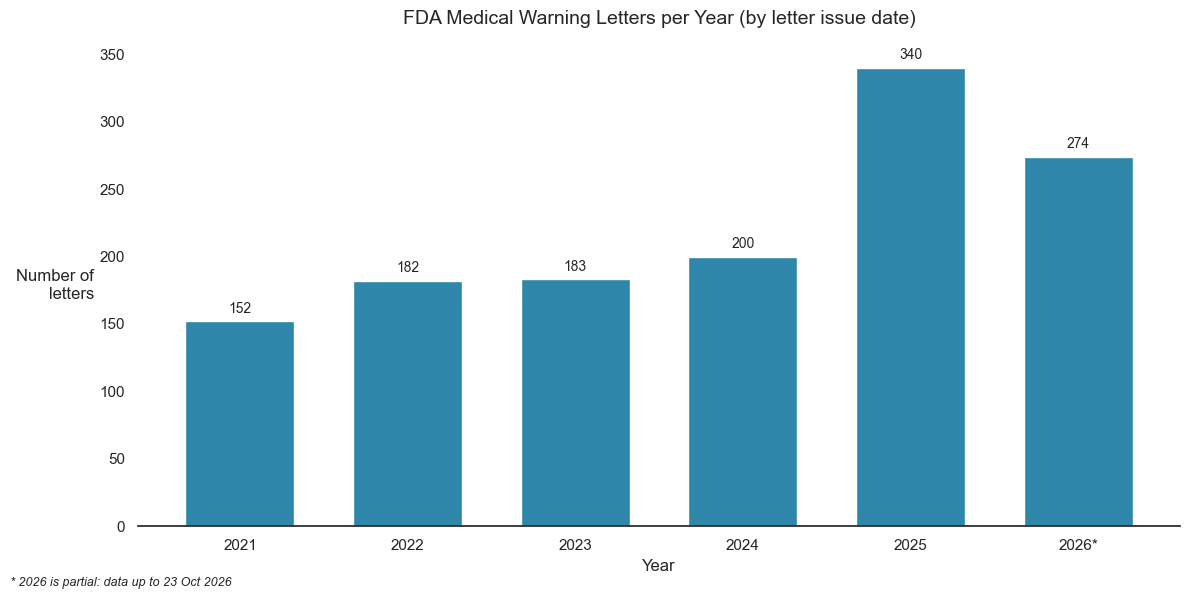

 Year  Count
 2021    152
 2022    182
 2023    183
 2024    200
 2025    340
 2026    274


In [18]:
letters_per_year = (letters["year"].value_counts().sort_index()
                    .reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0)
                    .rename_axis("Year").reset_index(name="Count"))
partial_year = LAST_DATE.year if LAST_DATE.month < 12 else None
labels_x = [f"{y}*" if y == partial_year else str(y) for y in letters_per_year["Year"]]

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(labels_x, letters_per_year["Count"], color="#2E86AB", width=0.65)
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_title("FDA Medical Warning Letters per Year (by letter issue date)", fontsize=14, pad=15)
ax.set_xlabel("Year")
ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
if partial_year:
    fig.text(0.01, 0.01, f"* {partial_year} is partial: data up to {LAST_DATE:%d %b %Y}", fontsize=9, style="italic")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(letters_per_year.to_string(index=False))

## 4. Dominant Terms (TF-IDF)

### 4.1 מילות עצירה
אותה רשימה של מילים "משפטיות" וקבועות כמו קודם, **חוץ ממילים שמתארות נושא** (`covid`, `sanitizer`, `compounding`, `device`, `hand`...). אותן כבר לא מוחקים, כי הן בדיוק מה שמבדיל בין סוגי מכתבים. נוספו מילים כלליות שעלו בגרף הישן (`including`, `address`, `united`, `states`...).

In [19]:
BOILERPLATE = [
    'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
    'received', 'response', 'inspections', 'investigations', 'food', 'drug', 'drugs',
    'administration', 'intended', 'use', 'violation', 'violations', 'substance',
    'substances', 'requirements', 'prohibited', 'commerce', 'interstate', 'within',
    'days', 'working', 'office', 'sincerely', 'director', 'center', 'care', 'adulterated',
    'misbranded', 'insanitary', 'conditions', 'cgmp', 'current', 'good', 'manufacturing',
    'practice', 'regulations', 'facility', 'inspection', 'investigator', 'review',
    'observed', 'specific', 'including', 'failure', 'failed', 'establish', 'procedures',
    'written', 'assure', 'identity', 'strength', 'quality', 'purity', 'regulatory',
    'legal', 'action', 'actions', 'address', 'steps', 'taken', 'correct', 'prevent',
    'recurrence', 'conclusions', 'investigate', 'thoroughly', 'unexplained',
    'discrepancy', 'batch', 'component', 'components', 'meet', 'specifications',
    'distributed', 'lots', 'lot', 'testing', 'test', 'results', 'analytical',
    'laboratory', 'records', 'record', 'control', 'controls', 'unit', 'responsibility',
    'authority', 'approve', 'reject', 'refer', 'case', 'number', 'date', 'dated',
    'title', 'label', 'labeling', 'website', 'internet', 'offers', 'sale', 'introduced',
    'solution', 'solutions', 'delivered', 'introduction', 'violates', 'sections',
    'meaning', 'federal', 'cosmetic', 'approved', 'application', 'applications',
    'effect', 'pursuant', 'evident', 'basis', 'legally', 'marketed', 'without',
    'gdufa', 'generic', 'user', 'fee', 'amendments', 'reauthorization', 'fiscal',
    'years', 'iii', 'commitment', 'eligible', 'post', 'meeting', 'obtain',
    'preliminary', 'feedback', 'adequacy', 'completeness', 'plans', 'content',
    'regulated', 'certified', 'medically', 'supervised', 'healthcare', 'setting',
    'hospitals', 'surgical', 'centers', 'emergency', 'departments', 'management',
    'acute', 'pain', 'severe', 'enough', 'require', 'opioid', 'analgesic',
    'alternative', 'treatments', 'inadequate', 'href', 'com', 'b4', 'variant',
    'url', 'http', 'https', 'ampoule', 'www', 'net', 'org', 'dear', 'mr', 'ms',
    'dr', 'attention', 'att', 'warning', 'include', 'unapproved', 'ensure',
    'appropriate', 'new', 'provide', 'process', 'data', 'information',
    'stated', 'noted', 'determine', 'found', 'described', 'regarding',
    'additionally', 'regard', 'follows', 'following', 'referred', 'indicated',
    'requires', 'provides', 'determines', 'available', 'additional', 'conducted',
    'required', 'documents', 'documentation', 'submit', 'submitted', 'copies',
    'copy', 'evidence', 'implementation', 'evaluate', 'evaluation', 'reviewed',
    'assessment', 'necessary', 'time', 'listed', 'items', 'item', 'paragraph',
    'order', 'clearly', 'subject', 'provisions', 'contained', 'issue', 'issued',
    'receive', 'sending', 'sent', 'reply', 'replying', 'contact', 'finally',
    'know', 'bring', 'closeout', 'observations', 'applicable', 'laws', 'serious',
    'problems', 'systems', 'prompt', 'marketing', 'distribute', 'sell', 'sold',
    'distribution', 'commercial', 'cfr', 'part', 'parts', 'subpart', 'title21',
    '21cfr', 'statute', 'did', 'used', 'plan', 'program', 'gov', 'recipient',
    'letters', 'fdca', 'adequate', 'research', 'risk', 'equipment', 'corrective',
    'manufacture', 'limited', 'health', 'treatment', 'person',
    'audit', 'protocol', 'procedure', 'report', 'reports', 'standard', 'standards',
    'method', 'methods', 'parameter', 'parameters', 'specification', 'preventive',
    'capa', 'sop', 'master', 'production', 'operations', 'performed', 'personnel',
    'staff', 'trained', 'training', 'qualification', 'validated', 'released',
    'quarantine', 'sampling', 'sample', 'samples', 'collected', 'collection',
    'analysis', 'analyzed', 'tested', 'tester', 'third', 'party', 'vendor',
    'supplier', 'contract', 'site', 'sites', 'line', 'lines', 'room', 'rooms',
    'area', 'areas', 'zone', 'zones', 'environment', 'environmental',
    'active', 'particular', 'clinical', 'ingredient', 'ingredients',
    'concerning', 'conduct', 'misleading', 'chemical', 'immediate', 'clean',
    'validate', 'validation', 'periodic', 'initial',
    'comprehensive', 'based', 'receipt', 'remediation',
    # added: generic words that topped the old c-TF-IDF chart
    'united', 'states', 'stating', 'addressed', 'paragraphs', 'also', 'however',
    'please', 'company', 'firms', 'may', 'must', 'should', 'would', 'could',
]
# Words that describe a TOPIC are kept on purpose (they were removed before)
TOPIC_WORDS = {'covid', 'coronavirus', 'sanitizer', 'sanitizers', 'compounding',
               'device', 'devices', 'hand'}

base_stop_words = sk_text.ENGLISH_STOP_WORDS.union(BOILERPLATE) - TOPIC_WORDS
print(f"{len(base_stop_words)} stop words")

681 stop words


### 4.2 ניקוי טקסט
כמו קודם: מוחק קישורים, מספרים וסימנים, ומעביר לאותיות קטנות. עובד על גוף המכתב.

In [20]:
def preprocess(text_in):
    text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
    text_in = re.sub(r'\b\d+\b', ' ', text_in)
    text_in = re.sub(r'[^a-zA-Z\s]', ' ', text_in)
    text_in = re.sub(r'\s+', ' ', text_in).strip()
    return text_in.lower()

clean_texts = [preprocess(t) for t in texts]
print(f"🧹 {len(clean_texts)} texts cleaned.")

🧹 1331 texts cleaned.


### 4.3 TF-IDF על מילים, צמדים ושלשות
וקטורייזר אחד ל-1 עד 3 מילים. הציון של כל מונח הוא סכום ה-TF-IDF שלו בכל המכתבים.
* `max_df=0.60` – מונח שמופיע ביותר מ-60% מהמכתבים הוא נוסח קבוע ונזרק.
* `min_df` – מונח שמופיע בפחות מ-1% מהמכתבים נזרק (רעש).
* `sublinear_tf` – מכתב שחוזר על מילה 40 פעמים לא משתלט על התוצאה.

In [21]:
n_docs = len(clean_texts)
tfidf_terms = TfidfVectorizer(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    ngram_range=(1, 3),
    max_df=0.60,
    min_df=max(2, int(n_docs * 0.01)),
    sublinear_tf=True,
    max_features=20000,
)
mat_terms = tfidf_terms.fit_transform(clean_texts)
all_df = pd.DataFrame({
    "Term":   tfidf_terms.get_feature_names_out(),
    "Weight": np.asarray(mat_terms.sum(axis=0)).ravel(),
})
all_df["Type"] = all_df["Term"].str.split().str.len().map({1: "Unigram", 2: "Bigram", 3: "Trigram"})
all_df = all_df.sort_values("Weight", ascending=False).reset_index(drop=True)
print(f"{len(all_df)} terms")

14454 terms


### 4.4 שתי רשימות: חופשית וקלינית
* **רשימה A – חופשית:** 25 המונחים החזקים, בלי שום סינון ידני. זו התמונה "האובייקטיבית".
* **רשימה B – קלינית:** רק מונחים שמכילים שורש קליני/מיקרוביולוגי (`clinical_roots`), חוץ מצירופים ברשימה השחורה. זו התמונה הממוקדת, ובעבודה צריך לכתוב במפורש שהיא תלויה ברשימת השורשים.

בשתי הרשימות: **בלי מכפילים** (הוסרו ה-×1.4 / ×1.8 השרירותיים), וכל מושג מופיע **פעם אחת** (`dedupe_terms`).

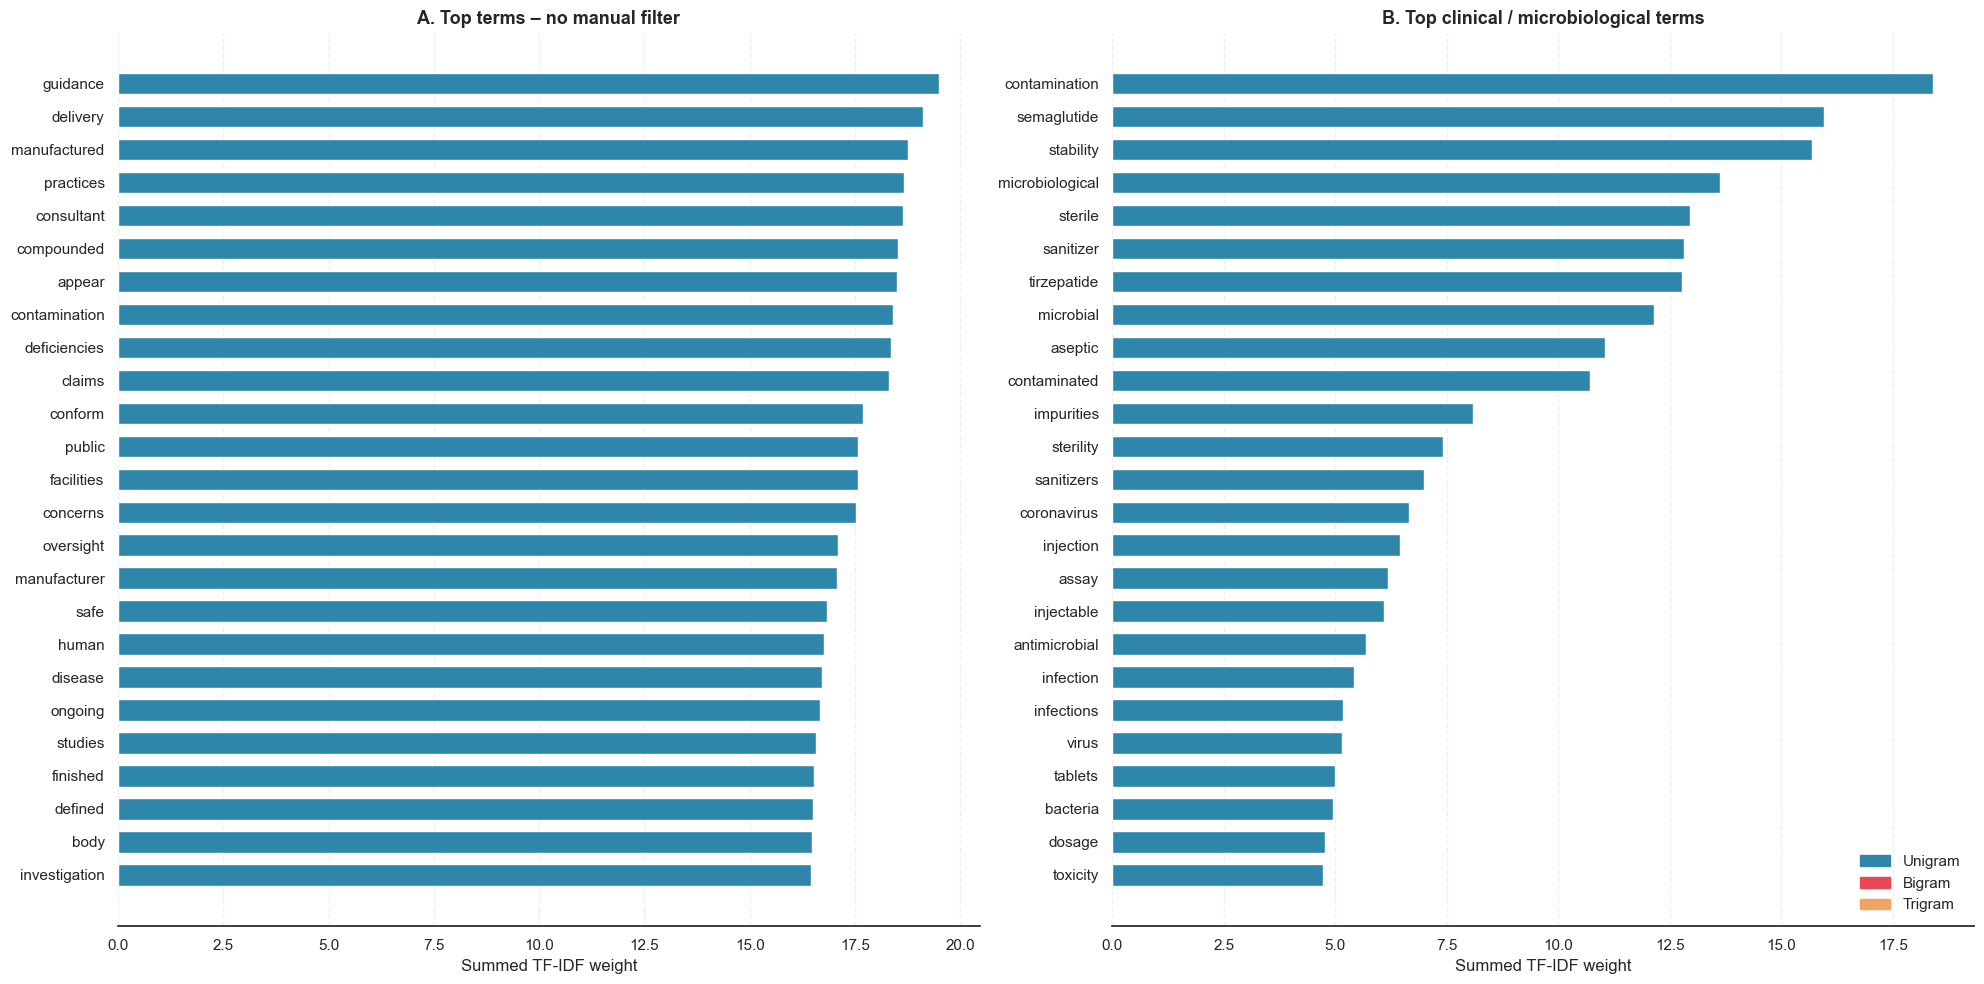

           Term    Type    Weight
  contamination Unigram 18.401001
    semaglutide Unigram 15.959881
      stability Unigram 15.686164
microbiological Unigram 13.623150
        sterile Unigram 12.957889
      sanitizer Unigram 12.817819
    tirzepatide Unigram 12.771066
      microbial Unigram 12.157741
        aseptic Unigram 11.038865
   contaminated Unigram 10.712673
     impurities Unigram  8.079116
      sterility Unigram  7.410667
     sanitizers Unigram  6.985338
    coronavirus Unigram  6.645400
      injection Unigram  6.442777
          assay Unigram  6.187440
     injectable Unigram  6.102253
  antimicrobial Unigram  5.681071
      infection Unigram  5.411104
     infections Unigram  5.169631
          virus Unigram  5.142012
        tablets Unigram  4.995759
       bacteria Unigram  4.957963
         dosage Unigram  4.768579
       toxicity Unigram  4.720407


In [22]:
NGRAM_BLACKLIST = {
    'misleading particular', 'concerning compounded', 'conduct clinical',
    'chemical microbiological', 'clinical studies', 'remediation given',
    'remediated stability', 'contents compoundinginspections', 'compoundinginspections',
    'repreparation', 'given remediation', 'given specific',
}
clinical_roots = [
    'steril', 'contamin', 'microbio', 'semaglu', 'tirzepa', 'infect', 'bacteri',
    'virus', 'viral', 'aseptic', 'impurit', 'validat', 'stabil', 'potenc', 'assay',
    'sanitiz', 'hygien', 'endotoxin', 'pyrogen', 'toxic', 'dosage', 'formulat',
    'capsule', 'tablet', 'inject', 'vial', 'lyophil', 'reconstitut', 'excipient',
    'preservat', 'antibiotic', 'pathogen', 'fungal', 'fungi', 'bioburden',
    'autoclave', 'depyrogenat', 'cleanroom', 'microbial', 'particulat',
]

def is_clinical(term):
    return any(root in term for root in clinical_roots)

def top_unique(df_terms, n=25):
    keep = dedupe_terms(df_terms["Term"].tolist(), n)
    return df_terms.set_index("Term").loc[keep].reset_index()

top_free = top_unique(all_df)
clin = all_df[all_df["Term"].apply(is_clinical) & ~all_df["Term"].isin(NGRAM_BLACKLIST)]
top_clin = top_unique(clin)

type_colors = {"Unigram": "#2E86AB", "Bigram": "#E84855", "Trigram": "#F4A261"}
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, df_t, title in [(axes[0], top_free, "A. Top terms – no manual filter"),
                        (axes[1], top_clin, "B. Top clinical / microbiological terms")]:
    ax.barh(df_t["Term"], df_t["Weight"], color=[type_colors[t] for t in df_t["Type"]], height=0.65)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Summed TF-IDF weight")
    ax.xaxis.grid(True, linestyle="--", alpha=0.3)
    sns.despine(ax=ax, left=True)
axes[1].legend(handles=[mpatches.Patch(color=c, label=t) for t, c in type_colors.items()],
               frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(top_clin[["Term", "Type", "Weight"]].to_string(index=False))

## 5. Topic Clustering with K-Means

### 5.1 מטריצת TF-IDF
כל מכתב הופך לשורה של מספרים (ציון לכל מילה וצמד מילים). אותה מטריצה משמשת גם לשמות הקבוצות בסעיף 7.

In [23]:
tfidf = TfidfVectorizer(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    ngram_range=(1, 2),
    max_df=0.60,
    min_df=5,
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(clean_texts)
feature_names = tfidf.get_feature_names_out()
print(f"TF-IDF matrix: {tfidf_matrix.shape[0]} letters × {tfidf_matrix.shape[1]} terms")

TF-IDF matrix: 1331 letters × 19933 terms


### 5.2 כמה קבוצות? (Silhouette)
**Silhouette** מודד כמה כל מכתב קרוב לקבוצה שלו לעומת הקבוצה השכנה. הטווח הוא בין ‎-1 ל-1, וגבוה יותר = חלוקה ברורה יותר. מריצים K-Means ל-k=2..8 ובוחרים את ה-k עם הציון הגבוה.

אם רוצים מספר אחר מסיבה מוצדקת (למשל 3 כדי להשוות לעבודה קודמת), כותבים אותו ב-`K_KMEANS_OVERRIDE` ומסבירים בעבודה.

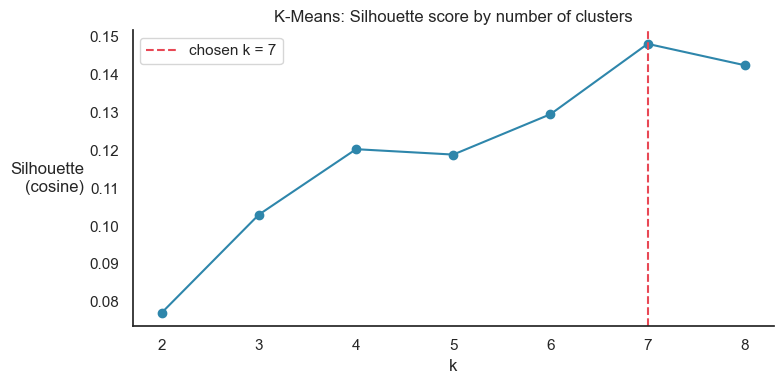

{2: np.float64(0.077), 3: np.float64(0.103), 4: np.float64(0.12), 5: np.float64(0.119), 6: np.float64(0.129), 7: np.float64(0.148), 8: np.float64(0.142)}


In [24]:
K_RANGE = range(2, 9)
K_KMEANS_OVERRIDE = None

sil_kmeans = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(tfidf_matrix)
    sil_kmeans[k] = silhouette_score(tfidf_matrix, km.labels_, metric="cosine")

K_KMEANS = K_KMEANS_OVERRIDE or max(sil_kmeans, key=sil_kmeans.get)

plt.figure(figsize=(8, 4))
plt.plot(list(sil_kmeans), list(sil_kmeans.values()), marker="o", color="#2E86AB")
plt.axvline(K_KMEANS, color="#E84855", linestyle="--", label=f"chosen k = {K_KMEANS}")
plt.title("K-Means: Silhouette score by number of clusters")
plt.xlabel("k"); plt.ylabel("Silhouette\n(cosine)", **HORIZONTAL_YLABEL); plt.legend(); sns.despine()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in sil_kmeans.items()})

### 5.3 אימון K-Means ותיאור הקבוצות
השמות נוצרים **אוטומטית** מהמילים המבדלות, ולכל קבוצה מודפס מה ה-FDA כתב בשדה הנושא של המכתבים שבה.

In [25]:
kmeans = KMeans(n_clusters=K_KMEANS, random_state=RANDOM_STATE, n_init=10).fit(tfidf_matrix)
kmeans_labels = kmeans.labels_
letters["kmeans_cluster"] = kmeans_labels + 1

kmeans_dist  = distinctive_terms(kmeans_labels, tfidf_matrix, feature_names)
kmeans_names = cluster_names(kmeans_dist)
cluster_profile(kmeans_labels, kmeans_names)


📁 C1: subjects · investigational · study  —  75 letters
   FDA subject lines:
       45%  Clinical Investigator
       11%  Clinical Investigator (Sponsor)
        7%  Bioresearch Monitoring Program/IRB
   Example companies: Adarsh Daswani, M.D.; Adnan Dahdul, MD; American Behavioral Research Institute, LLC; Americo F. Padilla, M.D.

📁 C2: webpage · occurrence complies · fdaadvisory  —  461 letters
   FDA subject lines:
       19%  Unapproved New Drugs/Misbranded
       13%  Compounding Pharmacy/Adulterated Drug Products
        9%  Deviations/CFR/Regulations for Human Cells, Tissues & Cellular Products (HCT/Ps)
   Example companies: 123Herbals; 4U Health; 7Tabz Retail, LLC; Abbott Laboratories

📁 C3: hand sanitizer · antiseptic · alcohol  —  61 letters
   FDA subject lines:
       49%  Finished Pharmaceuticals/Unapproved New Drug/Misbranded/Adulterated
       13%  CGMP/Finished Pharmaceuticals/Unapproved New Drug/Misbranded/Adulterated
       11%  CGMP/Finished Pharmaceuticals/Adulte

### 5.4 ציור הקבוצות (TruncatedSVD)
TruncatedSVD מכווץ את מטריצת ה-TF-IDF ל-2 ממדים **רק לציור**. החלוקה עצמה נעשתה במרחב המלא.

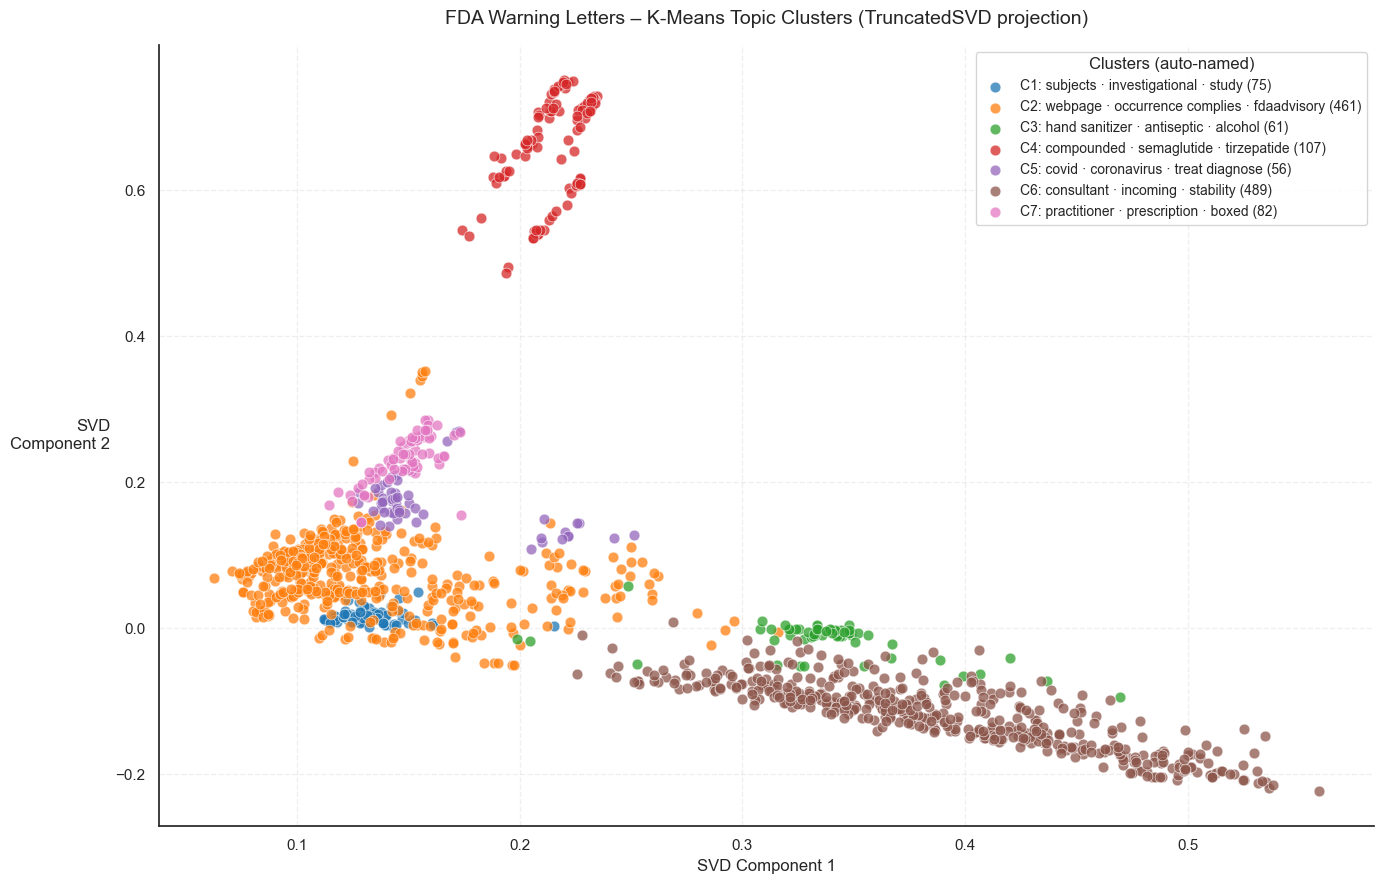

In [26]:
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
svd_xy = svd.fit_transform(tfidf_matrix)
km_colors = sns.color_palette("tab10", K_KMEANS)

sns.set_theme(style="white")
plt.figure(figsize=(14, 9))
for c in range(K_KMEANS):
    m = kmeans_labels == c
    plt.scatter(svd_xy[m, 0], svd_xy[m, 1], color=km_colors[c], alpha=0.75,
                edgecolors="w", s=60, linewidths=0.5, label=f"{kmeans_names[c]} ({m.sum()})")
plt.title("FDA Warning Letters – K-Means Topic Clusters (TruncatedSVD projection)", fontsize=14, pad=15)
plt.xlabel("SVD Component 1"); plt.ylabel("SVD\nComponent 2", **HORIZONTAL_YLABEL)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Clusters (auto-named)", fontsize=10, loc="best")
sns.despine(); plt.tight_layout(); plt.show()

## 6. Semantic Clustering with Sentence-BERT

### 6.1 וקטור לכל מכתב – על **כל** המכתב
המודל `all-MiniLM-L6-v2` קורא עד 256 טוקנים (~200 מילים). לכן:
1. כל מכתב מחולק לקטעים של 150 מילים (עד 20 קטעים = 3,000 מילים).
2. כל קטע הופך לווקטור.
3. הווקטור של המכתב = הממוצע של הקטעים שלו.

כך הווקטור מייצג את התוכן של כל המכתב, ולא רק את הפתיחה. ב-GPU זה לוקח כמה דקות.

In [27]:
WORDS_PER_CHUNK = 150
MAX_CHUNKS = 20

def clean_for_embedding(t):
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def word_chunks(t, n=WORDS_PER_CHUNK):
    w = t.split()
    return [" ".join(w[i:i + n]) for i in range(0, len(w), n)] or [""]

chunk_texts, chunk_owner = [], []
for i, t in enumerate(texts):
    parts = word_chunks(clean_for_embedding(t))[:MAX_CHUNKS]
    chunk_texts += parts
    chunk_owner += [i] * len(parts)
chunk_owner = np.array(chunk_owner)
print(f"🧠 {len(chunk_texts)} chunks ({len(chunk_texts) / len(texts):.1f} per letter)")

sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
chunk_emb = sbert_model.encode(chunk_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

embeddings = np.vstack([chunk_emb[chunk_owner == i].mean(axis=0) for i in range(len(texts))])
embeddings /= np.linalg.norm(embeddings, axis=1, keepdims=True)
print(f"✅ Embedding matrix: {embeddings.shape}")

🧠 17416 chunks (13.1 per letter)


Batches:   0%|          | 0/273 [00:00<?, ?it/s]

Batches:   0%|          | 1/273 [00:00<01:27,  3.12it/s]

Batches:   1%|          | 2/273 [00:00<01:08,  3.95it/s]

Batches:   1%|          | 3/273 [00:00<01:02,  4.32it/s]

...

Batches:  99%|█████████▊| 269/273 [00:57<00:00,  6.16it/s]

Batches:  99%|█████████▉| 271/273 [00:57<00:00,  8.59it/s]

Batches: 100%|██████████| 273/273 [00:57<00:00,  7.43it/s]

Batches: 100%|██████████| 273/273 [00:57<00:00,  4.74it/s]

✅ Embedding matrix: (1331, 384)


### 6.2 עץ היררכי (Ward) ובחירת מספר הקבוצות
בונים את העץ פעם אחת, חותכים אותו ל-k=2..8 ובודקים Silhouette לכל חיתוך. גם כאן אפשר לקבוע מספר ידנית עם `K_SEMANTIC_OVERRIDE`.

**חשוב:** זו החלוקה היחידה של סעיפים 6–7. בגרסה הקודמת היו שתי חלוקות שונות (טקסט נקי וטקסט גולמי), ולכן "קבוצה 1" לא הייתה אותה קבוצה בשני הסעיפים.

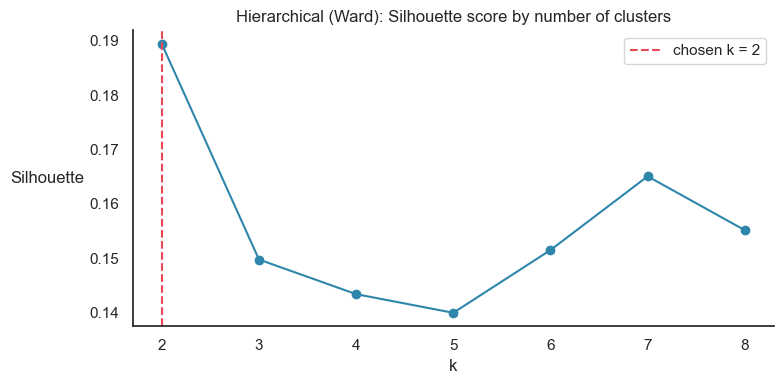

{2: np.float32(0.189), 3: np.float32(0.15), 4: np.float32(0.143), 5: np.float32(0.14), 6: np.float32(0.152), 7: np.float32(0.165), 8: np.float32(0.155)}
Cluster sizes: [502, 829]


In [28]:
Z = linkage(embeddings, method="ward")
K_SEMANTIC_OVERRIDE = None

sil_ward = {k: silhouette_score(embeddings, fcluster(Z, t=k, criterion="maxclust"))
            for k in K_RANGE}
K_SEMANTIC = K_SEMANTIC_OVERRIDE or max(sil_ward, key=sil_ward.get)
hier_labels = fcluster(Z, t=K_SEMANTIC, criterion="maxclust") - 1
letters["semantic_cluster"] = hier_labels + 1

plt.figure(figsize=(8, 4))
plt.plot(list(sil_ward), list(sil_ward.values()), marker="o", color="#2E86AB")
plt.axvline(K_SEMANTIC, color="#E84855", linestyle="--", label=f"chosen k = {K_SEMANTIC}")
plt.title("Hierarchical (Ward): Silhouette score by number of clusters")
plt.xlabel("k"); plt.ylabel("Silhouette", **HORIZONTAL_YLABEL); plt.legend(); sns.despine()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in sil_ward.items()})
print("Cluster sizes:", np.bincount(hier_labels).tolist())

## 7. Keywords per Semantic Cluster + Maps

### 7.1 המילים המבדלות של כל קבוצה (במקום c-TF-IDF)
**למה ה-c-TF-IDF הישן נכשל:** הוא חיבר כל קבוצה למסמך אחד והריץ TF-IDF על 3 מסמכים בלבד. עם 3 מסמכים, מילה שמופיעה בכל הקבוצות נענשת רק פי 1.7 בערך, ולכן מילים כלליות שמופיעות הרבה (`including`, `address`, `https`) ניצחו.

**הציון החדש:** לכל מילה, הממוצע שלה במכתבים של הקבוצה **פחות** הממוצע שלה בשאר המכתבים. מילה שנפוצה בכל מקום מקבלת כמעט אפס. השמות של הקבוצות נגזרים מהציון הזה, ולא נכתבים ידנית.

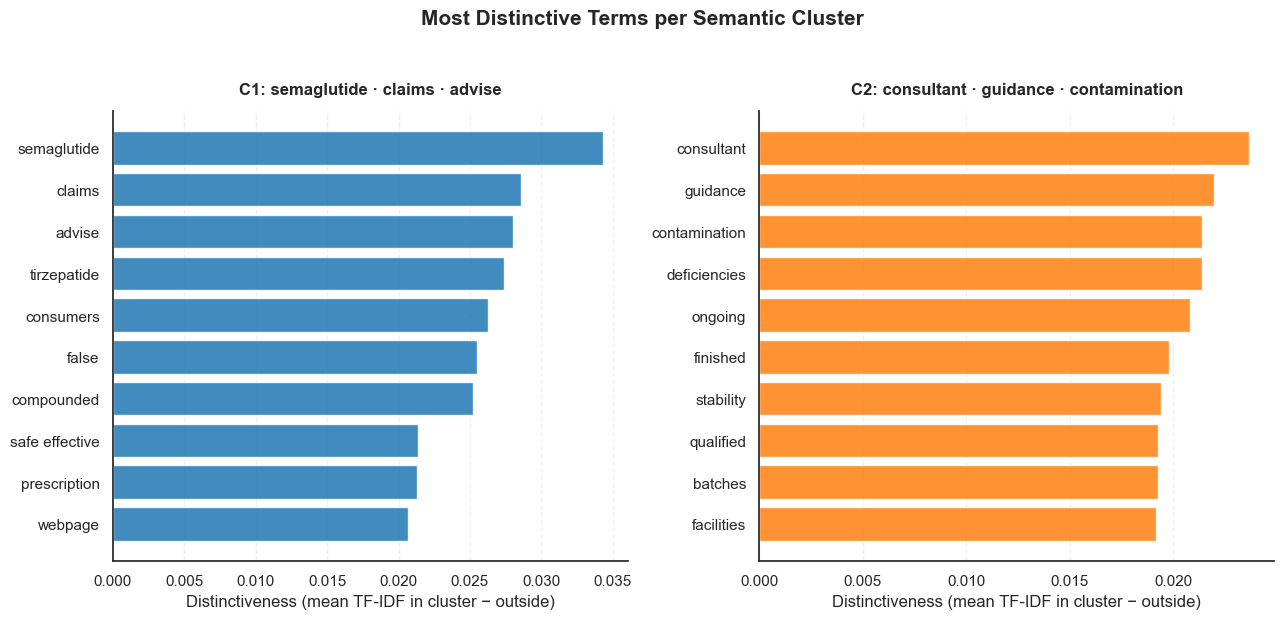


📁 C1: semaglutide · claims · advise  —  502 letters
   FDA subject lines:
       22%  Unapproved New Drugs/Misbranded
       11%  False & Misleading Claims/Misbranded (Telehealth)
       10%  Unlawful Sale of Unapproved and Misbranded Drugs to United States Consumers Over the Inter
   Example companies: 123Herbals; 247rxpill.in; 24HrDoc, Inc. dba 24HrDoc; 7Tabz Retail, LLC

📁 C2: consultant · guidance · contamination  —  829 letters
   FDA subject lines:
       43%  CGMP/Finished Pharmaceuticals/Adulterated
        7%  Compounding Pharmacy/Adulterated Drug Products
        6%  CGMP/Active Pharmaceutical Ingredient (API)/Adulterated
   Example companies: 3D Imaging Drug Design and Development LLC; 4U Health; AAA Cosmetica, SA de CV; AACE Pharmaceuticals, Inc.


In [29]:
sem_dist   = distinctive_terms(hier_labels, tfidf_matrix, feature_names)
sem_names  = cluster_names(sem_dist)
sem_colors = sns.color_palette("tab10", K_SEMANTIC)

plot_distinctive(sem_dist, sem_names, "Most Distinctive Terms per Semantic Cluster", sem_colors)
cluster_profile(hier_labels, sem_names)

### 7.2 מפת t-SNE + דנדרוגרמה
* **שמאל – t-SNE:** כל נקודה היא מכתב. נקודות קרובות = מכתבים דומים. המרחק בין "איים" שונים וגודל האיים **לא** אומרים כלום.
* **ימין – דנדרוגרמה:** העץ. הגובה של כל חיבור = כמה הקבוצות שונות. הקו המקווקו הוא המקום שבו העץ נחתך. המספרים בסוגריים = כמה מכתבים בכל ענף.

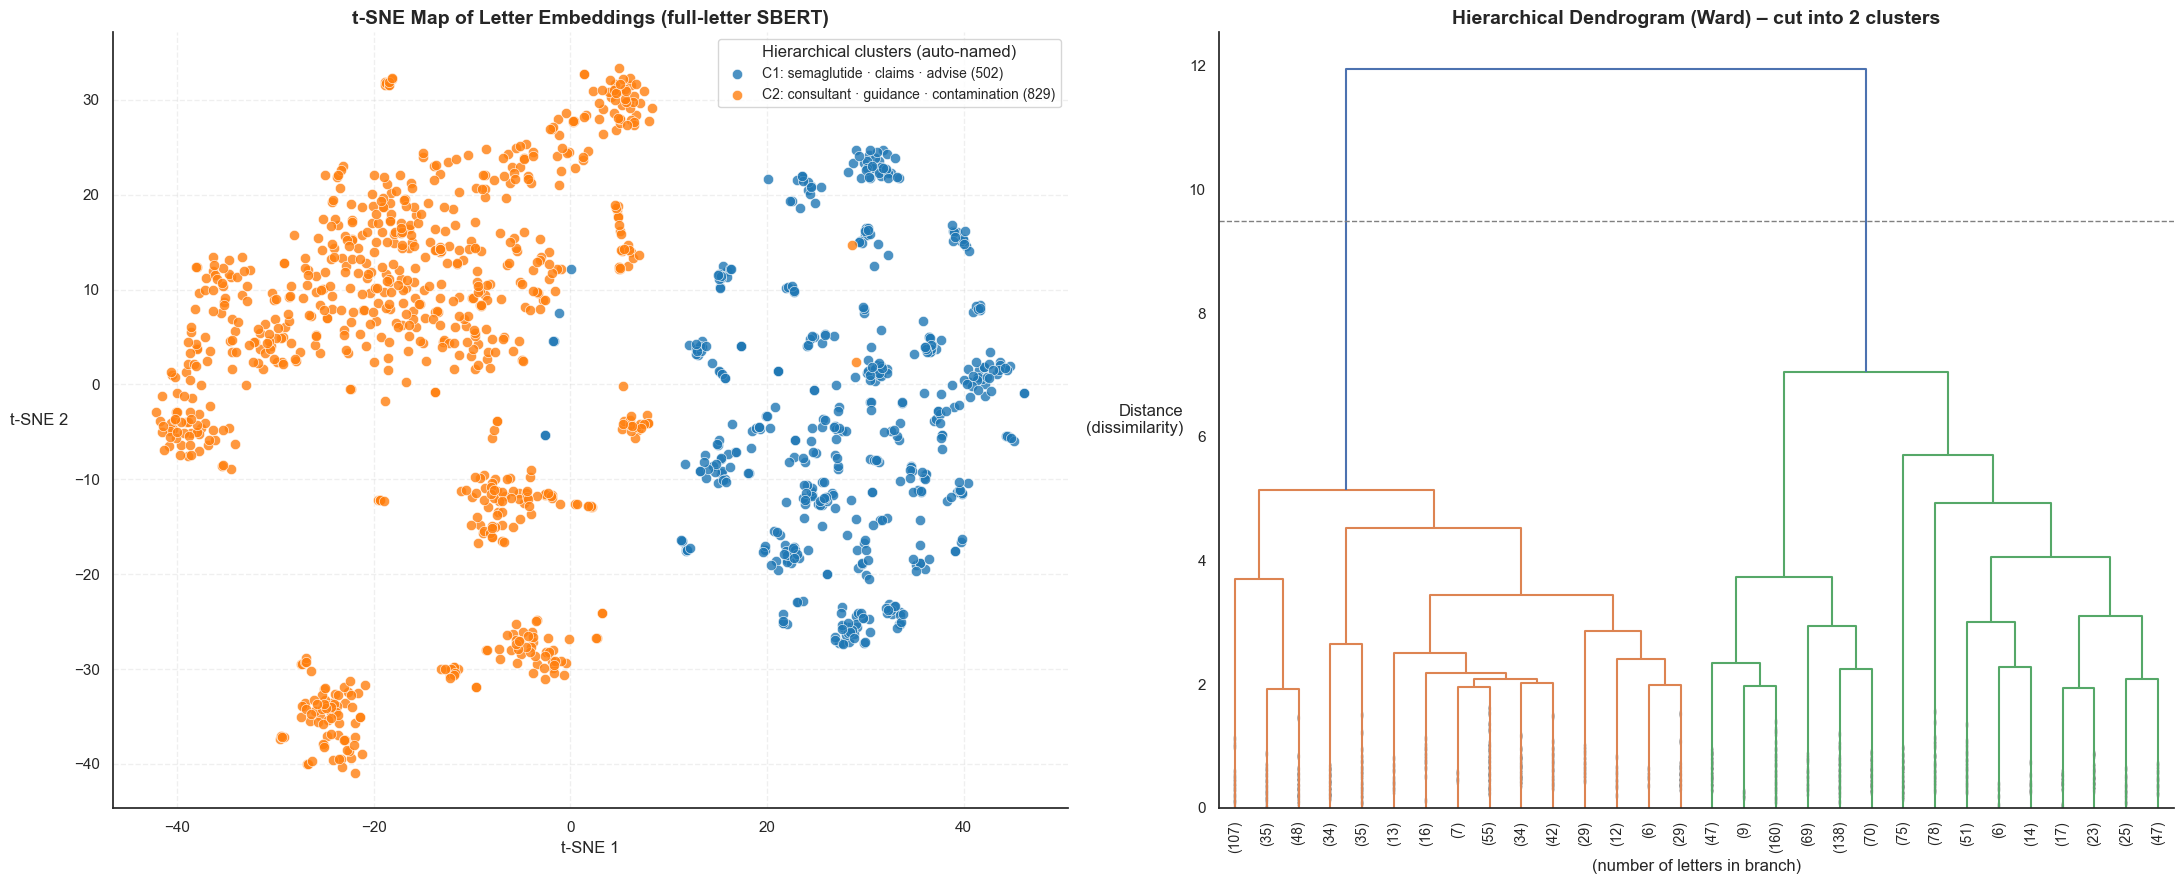

In [30]:
tsne_xy = TSNE(n_components=2, perplexity=30, init="random",
               random_state=RANDOM_STATE, max_iter=1000).fit_transform(embeddings)

sns.set_theme(style="white")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
for c in range(K_SEMANTIC):
    m = hier_labels == c
    ax1.scatter(tsne_xy[m, 0], tsne_xy[m, 1], color=sem_colors[c], alpha=0.8,
                edgecolors="w", s=55, linewidths=0.5, label=f"{sem_names[c]} ({m.sum()})")
ax1.set_title("t-SNE Map of Letter Embeddings (full-letter SBERT)", fontsize=14, fontweight="bold")
ax1.set_xlabel("t-SNE 1"); ax1.set_ylabel("t-SNE 2", **HORIZONTAL_YLABEL)
ax1.grid(True, linestyle="--", alpha=0.3)
ax1.legend(title="Hierarchical clusters (auto-named)", fontsize=10, loc="best")
sns.despine(ax=ax1)

cut = (Z[-K_SEMANTIC, 2] + Z[-(K_SEMANTIC - 1), 2]) / 2
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax2, leaf_rotation=90,
           leaf_font_size=10, show_contracted=True, color_threshold=cut)
ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
ax2.set_title(f"Hierarchical Dendrogram (Ward) – cut into {K_SEMANTIC} clusters", fontsize=14, fontweight="bold")
ax2.set_xlabel("(number of letters in branch)"); ax2.set_ylabel("Distance\n(dissimilarity)", **HORIZONTAL_YLABEL)
sns.despine(ax=ax2)
plt.tight_layout(); plt.show()

### 7.3 האם שתי השיטות מסכימות?
טבלה של קבוצות K-Means מול הקבוצות הסמנטיות. אם רוב המכתבים של קבוצה אחת נופלים בקבוצה אחת של השיטה השנייה, שתי השיטות מצאו את אותו נושא, וזו ראיה חזקה שהנושא אמיתי.

In [31]:
display(pd.crosstab(letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1]),
                    letters["semantic_cluster"].map(lambda c: sem_names[c - 1]),
                    rownames=["K-Means"], colnames=["Semantic (SBERT)"]))

Semantic (SBERT),C1: semaglutide · claims · advise,C2: consultant · guidance · contamination
K-Means,,
C1: subjects · investigational · study,0,75
C2: webpage · occurrence complies · fdaadvisory,255,206
C3: hand sanitizer · antiseptic · alcohol,0,61
C4: compounded · semaglutide · tirzepatide,107,0
C5: covid · coronavirus · treat diagnose,56,0
C6: consultant · incoming · stability,2,487
C7: practitioner · prescription · boxed,82,0


## 8. Zero-Shot Classification with DeBERTa

### 8.1 GPU וטעינת המודל
בלי GPU השלב הזה איטי מאוד. ב-Colab: Runtime → Change runtime type → T4 GPU.

In [32]:
if torch.cuda.is_available():
    device = 0
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = -1
print("⚠️ No GPU – this section will be slow" if device == -1 else f"🚀 GPU detected ({device})")
classifier = pipeline("zero-shot-classification",
                      model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli", device=device)

🚀 GPU detected (mps)


Device set to use mps


### 8.2 קטגוריות וחלוקה לקטעים
* **הקטגוריות עודכנו לפי הנושאים הרשמיים של ה-FDA.** בגרסה הקודמת 3 מתוך 5 קטגוריות קיבלו יחד 6 מכתבים. בשדה הנושא של ה-FDA כמעט אין מכתבים על "safety reports" או "data integrity", אבל יש עשרות מכתבים על **Compounding** (רקיחה בבתי מרקחת), שלא הייתה לו קטגוריה. לכן יש עכשיו 4 קטגוריות: cGMP, תרופות לא מאושרות / שיווק מטעה, Compounding ומחקר קליני.
* כל קטגוריה מוכנסת למשפט (`HYPOTHESIS`), וזה עוזר למודל.
* **פיצול לקטעים:** הטקסט שהורד מופרד ב-`\n` בודד ולא ב-`\n\n`, ולכן בגרסה הקודמת כל מכתב היה "פסקה" אחת, ורק 1,000 התווים הראשונים (הכותרת) סווגו. עכשיו גוף המכתב מחולק לקטעים של עד 1,000 תווים, ומסווגים עד 8 קטעים לכל מכתב. הקוד מדפיס כמה קטעים יצאו בממוצע, כדי לוודא שהפיצול עובד.
* **הצבעה:** כל קטגוריה שעוברת סף 0.5 בקטע מקבלת קול. מנצחת הקטגוריה עם הכי הרבה קולות. בתיקו מנצחת הקטגוריה עם הציון הממוצע הגבוה.

In [33]:
TOPICS = {
    "manufacturing quality and cGMP violations":       "cGMP & Manufacturing Quality",
    "unapproved drugs, misbranding and false claims":  "Unapproved Drugs & Misbranding",
    "pharmacy drug compounding":                       "Drug Compounding",
    "clinical trials and research violations":         "Clinical & Research Violations",
}
UNCLASSIFIED = "Unclassified"
HYPOTHESIS = "This FDA warning letter paragraph is about {}."
THRESHOLD = 0.5
MAX_CHUNKS_PER_LETTER = 8

def paragraph_chunks(body, min_chars=200, max_chars=1000):
    pieces = []
    for line in body.split("\n"):
        line = line.strip()
        while len(line) > max_chars:
            cut = line.rfind(" ", 0, max_chars)
            cut = cut if cut > 0 else max_chars
            pieces.append(line[:cut]); line = line[cut:].strip()
        if line:
            pieces.append(line)
    chunks, cur = [], ""
    for p in pieces:
        if cur and len(cur) + len(p) + 1 > max_chars:
            chunks.append(cur); cur = p
        else:
            cur = f"{cur} {p}".strip()
        if len(cur) >= min_chars and len(cur) >= max_chars * 0.8:
            chunks.append(cur); cur = ""
    if cur:
        chunks.append(cur)
    return chunks

cls_texts, cls_owner = [], []
for i, b in enumerate(letters["body"]):
    parts = paragraph_chunks(b)[:MAX_CHUNKS_PER_LETTER]
    cls_texts += parts
    cls_owner += [i] * len(parts)
cls_owner = np.array(cls_owner)
chunks_per_letter = np.bincount(cls_owner, minlength=len(letters))
print(f"{len(cls_texts)} chunks to classify ({chunks_per_letter.mean():.1f} per letter)")
print(f"Letters with only 1 chunk: {(chunks_per_letter == 1).sum()} | with 0 chunks: {(chunks_per_letter == 0).sum()}")

10496 chunks to classify (7.9 per letter)
Letters with only 1 chunk: 0 | with 0 chunks: 0


### 8.3 הסיווג
השלב האיטי ביותר. התוצאה נשמרת ל-`letters_classified.csv`. אם Colab מתנתק, הרצה חוזרת של התא טוענת את התוצאה מהקובץ במקום לסווג שוב. כדי לסווג מחדש (למשל אחרי שינוי קטגוריות), מגדירים `RECLASSIFY = True`.

In [34]:
CLASSIFIED_OUT = DATA_DIR / "letters_classified.csv"
RECLASSIFY = False

topic_list = list(TOPICS)
cached = pd.read_csv(CLASSIFIED_OUT) if CLASSIFIED_OUT.exists() and not RECLASSIFY else None
if cached is not None and set(letters["url"]) <= set(cached["url"]) and set(cached["final_topic"]) <= set(topic_list) | {UNCLASSIFIED}:
    letters["final_topic"] = letters["url"].map(cached.set_index("url")["final_topic"])
    print(f"📂 Loaded saved classification from {CLASSIFIED_OUT}")
else:
    scores = np.zeros((len(cls_texts), len(topic_list)))
    BATCH = 128
    for s in tqdm(range(0, len(cls_texts), BATCH), desc="Classifying"):
        out = classifier(cls_texts[s:s + BATCH], candidate_labels=topic_list,
                         multi_label=True, hypothesis_template=HYPOTHESIS, batch_size=16)
        out = [out] if isinstance(out, dict) else out
        for j, res in enumerate(out):
            for lab, sc in zip(res["labels"], res["scores"]):
                scores[s + j, topic_list.index(lab)] = sc

    final_topic = []
    for i in range(len(letters)):
        s = scores[cls_owner == i]
        if len(s) == 0:
            final_topic.append(UNCLASSIFIED); continue
        votes = (s >= THRESHOLD).sum(axis=0)
        if votes.max() == 0:
            final_topic.append(UNCLASSIFIED); continue
        tied = np.flatnonzero(votes == votes.max())
        final_topic.append(topic_list[tied[np.argmax(s.mean(axis=0)[tied])]])

    letters["final_topic"] = final_topic
    letters.drop(columns=["text"]).to_csv(CLASSIFIED_OUT, index=False)

print(letters["final_topic"].value_counts().to_string())

Classifying:   0%|          | 0/82 [00:00<?, ?it/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Classifying:   1%|          | 1/82 [00:08<10:58,  8.13s/it]

Classifying:   2%|▏         | 2/82 [00:15<10:18,  7.73s/it]

Classifying:   4%|▎         | 3/82 [00:23<10:04,  7.65s/it]

...

Classifying:  98%|█████████▊| 80/82 [09:18<00:14,  7.09s/it]

Classifying:  99%|█████████▉| 81/82 [09:25<00:06,  6.86s/it]

Classifying: 100%|██████████| 82/82 [09:31<00:00,  6.78s/it]

Classifying: 100%|██████████| 82/82 [09:31<00:00,  6.97s/it]

final_topic
unapproved drugs, misbranding and false claims    589
manufacturing quality and cGMP violations         576
pharmacy drug compounding                          87
clinical trials and research violations            76
Unclassified                                        3


### 8.4 בדיקת דיוק מול הנושא הרשמי של ה-FDA
כאן משתמשים בשדה `subject` שה-FDA עצמו כתב לכל מכתב, והופכים אותו לקטגוריית ייחוס לפי מילות מפתח.

* זה **ייחוס משוער**: שדה הנושא לפעמים מכיל כמה נושאים (למשל `CGMP/Finished Pharmaceuticals/Unapproved New Drug/Misbranded`). במקרה כזה הקטגוריה נקבעת לפי הסדר: קליני → Compounding → cGMP → תרופות לא מאושרות / misbranding.
* המילים `Finished Pharmaceuticals` לבדן **לא** נחשבות cGMP. בגרסה הקודמת הן כן נחשבו, ולכן כ-100 מכתבים מסוג `Finished Pharmaceuticals/Unapproved New Drug/Misbranded` סומנו בטעות כ-cGMP.
* מכתבים שהנושא שלהם לא מתאים לאף כלל (למשל `Nonprescription/OTC`, ‏`HCT/Ps`, ‏`Failure to Register and List`) לא נכנסים לבדיקה.
* הקוד מדפיס את הנושאים הנפוצים, כדי שתוכל לבדוק שהכללים הגיוניים.

In [35]:
SUBJECT_RULES = [
    ("clinical trials and research violations",        r"clinical|investigator|sponsor|bioresearch|\birb\b|institutional review|bioequivalence"),
    ("pharmacy drug compounding",                      r"compounding|outsourcing"),
    ("manufacturing quality and cGMP violations",      r"cgmp|good manufacturing|active pharmaceutical|\bapi\b"),
    ("unapproved drugs, misbranding and false claims", r"misbrand|unapproved|new drug|false|misleading|labeling|internet|online"),
]

def subject_to_topic(subj):
    s = str(subj).lower()
    for topic, pattern in SUBJECT_RULES:
        if re.search(pattern, s):
            return topic
    return None

print("Most common FDA subject lines:")
print(letters["subject"].value_counts().head(15).to_string(), "\n")

letters["reference_topic"] = letters["subject"].apply(subject_to_topic)
ev = letters[letters["reference_topic"].notna()]
print(f"Letters with a reference label: {len(ev)} of {len(letters)} ({len(ev) / len(letters):.0%})")
print(f"Agreement of DeBERTa with the FDA subject: {(ev['final_topic'] == ev['reference_topic']).mean():.1%}\n")
print(classification_report(ev["reference_topic"], ev["final_topic"], zero_division=0))
display(pd.crosstab(ev["reference_topic"], ev["final_topic"],
                    rownames=["FDA subject"], colnames=["DeBERTa"]))

Most common FDA subject lines:
subject
CGMP/Finished Pharmaceuticals/Adulterated                                                                     363
Unapproved New Drugs/Misbranded                                                                               113
Compounding Pharmacy/Adulterated Drug Products                                                                 59
Unlawful Sale of Unapproved and Misbranded Drugs to United States Consumers Over the Internet (Telehealth)     58
False & Misleading Claims/Misbranded (Telehealth)                                                              55
Finished Pharmaceuticals/Unapproved New Drug/Misbranded                                                        49
CGMP/Active Pharmaceutical Ingredient (API)/Adulterated                                                        47
Deviations/CFR/Regulations for Human Cells, Tissues & Cellular Products (HCT/Ps)                               40
Nonprescription/OTC                              

DeBERTa,clinical trials and research violations,manufacturing quality and cGMP violations,pharmacy drug compounding,"unapproved drugs, misbranding and false claims"
FDA subject,,,,
clinical trials and research violations,73,0,0,0
manufacturing quality and cGMP violations,0,497,1,37
pharmacy drug compounding,0,30,30,0
"unapproved drugs, misbranding and false claims",2,6,56,466


### 8.4b בדיקה ידנית (מומלץ להגנה)
שדה הנושא הוא ייחוס משוער, ולכן כדאי לבדוק גם ידנית מדגם קטן:
1. התא מייצא 40 מכתבים אקראיים ל-`manual_check.csv`, עם הקישור, הנושא של ה-FDA והסיווג של DeBERTa.
2. פותחים את הקובץ באקסל, קוראים כל מכתב (הקישור), וממלאים בעמודה `manual_topic` את הקטגוריה הנכונה. השמות המותרים מודפסים מתחת לתא.
3. מריצים שוב את התא: אם העמודה מלאה, הוא מחשב את הדיוק של DeBERTa מול הבדיקה הידנית.

In [36]:
MANUAL_OUT = DATA_DIR / "manual_check.csv"

if not MANUAL_OUT.exists():
    sample = letters.sample(min(40, len(letters)), random_state=RANDOM_STATE)
    sample[["url", "company", "subject", "final_topic"]].assign(manual_topic="").to_csv(MANUAL_OUT, index=False)
    print(f"📝 Wrote {len(sample)} letters to {MANUAL_OUT} – fill in 'manual_topic' and run this cell again.")
    print("Allowed values:", topic_list + [UNCLASSIFIED])
else:
    manual = pd.read_csv(MANUAL_OUT, dtype={"manual_topic": str})
    manual["manual_topic"] = manual["manual_topic"].fillna("").str.strip()
    manual = manual[manual["manual_topic"] != ""]
    if manual.empty:
        print(f"'{MANUAL_OUT}' exists but 'manual_topic' is still empty.")
    else:
        acc = (manual["final_topic"] == manual["manual_topic"]).mean()
        print(f"✅ DeBERTa accuracy vs manual labels: {acc:.0%} on {len(manual)} letters")
        display(pd.crosstab(manual["manual_topic"], manual["final_topic"], rownames=["Manual"], colnames=["DeBERTa"]))

'data/manual_check.csv' exists but 'manual_topic' is still empty.


### 8.5 מגמות לפי שנה – במספרים ובאחוזים
* **שמאל:** מספר מכתבים מכל קטגוריה בכל שנה.
* **ימין:** **אחוז** מכלל המכתבים של אותה שנה. זה הגרף שמראה אם סדרי העדיפויות השתנו, כי הוא מנטרל את העובדה שבשנים מסוימות פשוט היו יותר מכתבים.
* לכל קטגוריה צבע קבוע משלה, והמקרא לפי השמות האמיתיים.

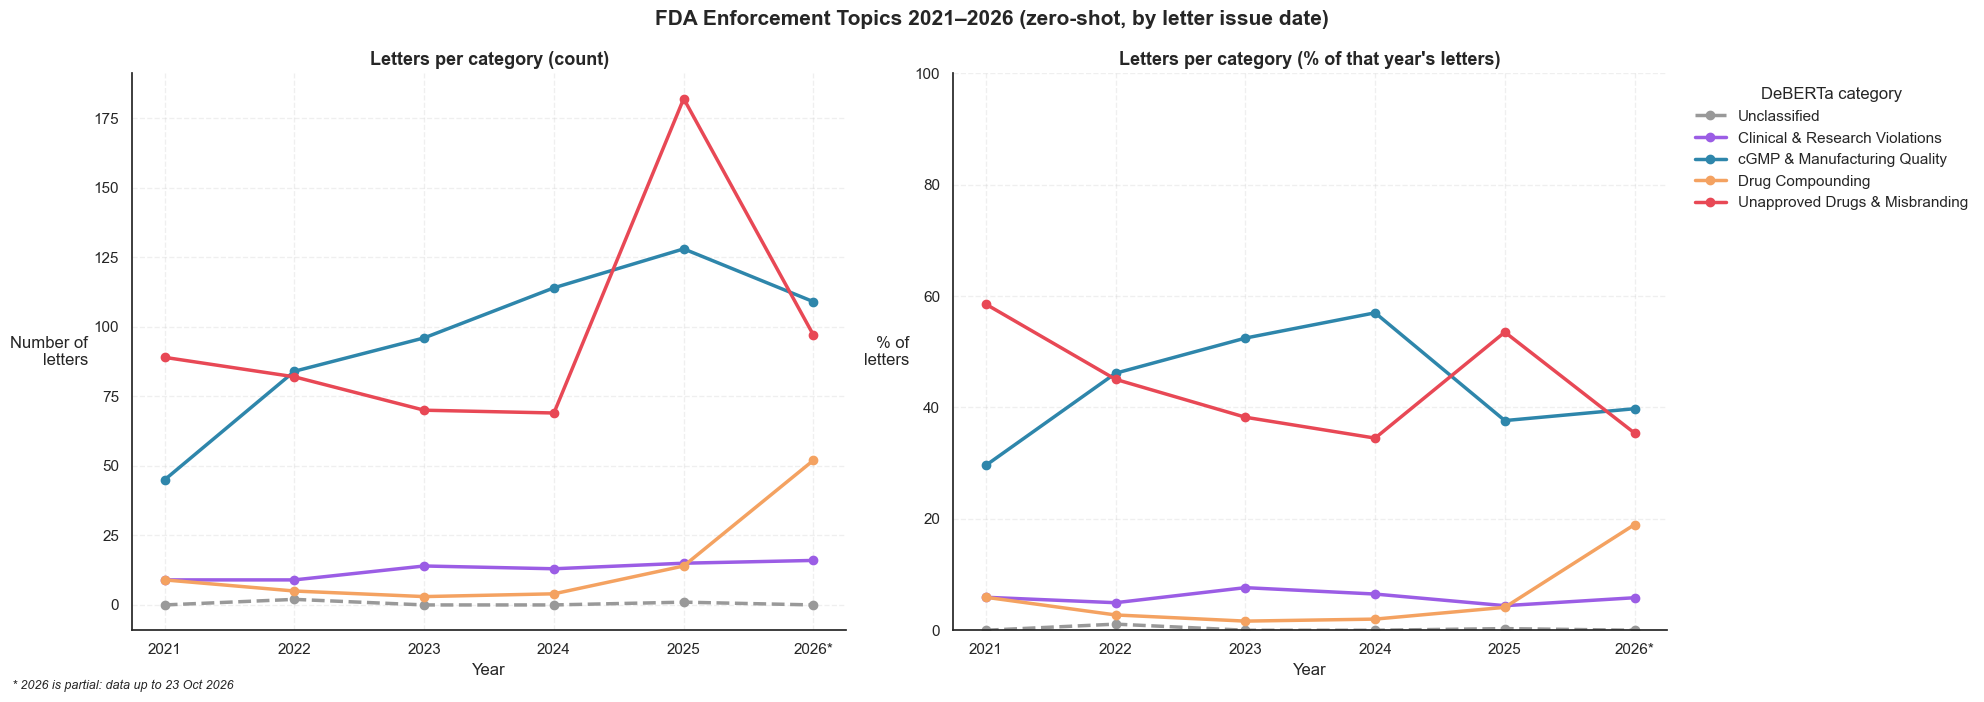

Share of letters per year (%):
final_topic  Unclassified  Clinical & Research Violations  cGMP & Manufacturing Quality  Drug Compounding  Unapproved Drugs & Misbranding
year                                                                                                                                     
2021                  0.0                             6.0                          30.0               6.0                            59.0
2022                  1.0                             5.0                          46.0               3.0                            45.0
2023                  0.0                             8.0                          52.0               2.0                            38.0
2024                  0.0                             6.0                          57.0               2.0                            34.0
2025                  0.0                             4.0                          38.0               4.0                            54.0
202

In [37]:
TOPIC_COLORS = {
    "manufacturing quality and cGMP violations":       "#2E86AB",
    "unapproved drugs, misbranding and false claims":  "#E84855",
    "pharmacy drug compounding":                       "#F4A261",
    "clinical trials and research violations":         "#9B5DE5",
    UNCLASSIFIED:                                      "#999999",
}
DISPLAY = {**TOPICS, UNCLASSIFIED: "Unclassified"}
years = list(range(YEAR_MIN, YEAR_MAX + 1))

yearly_counts = pd.crosstab(letters["year"], letters["final_topic"]).reindex(years, fill_value=0)
yearly_share = yearly_counts.div(yearly_counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
xt = [f"{y}*" if y == partial_year else str(y) for y in years]

sns.set_theme(style="white")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(20, 7))
for col in yearly_counts.columns:
    style = dict(color=TOPIC_COLORS.get(col, "black"), marker="o", linewidth=2.5,
                 linestyle="--" if col == UNCLASSIFIED else "-", label=DISPLAY.get(col, col))
    a1.plot(xt, yearly_counts[col].values, **style)
    a2.plot(xt, yearly_share[col].values, **style)
a1.set_title("Letters per category (count)", fontsize=13, fontweight="bold")
a1.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
a2.set_title("Letters per category (% of that year's letters)", fontsize=13, fontweight="bold")
a2.set_ylabel("% of\nletters", **HORIZONTAL_YLABEL); a2.set_ylim(0, 100)
for a in (a1, a2):
    a.set_xlabel("Year"); a.grid(True, linestyle="--", alpha=0.3); sns.despine(ax=a)
a2.legend(title="DeBERTa category", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("FDA Enforcement Topics 2021–2026 (zero-shot, by letter issue date)", fontsize=15, fontweight="bold")
if partial_year:
    fig.text(0.01, 0.01, f"* {partial_year} is partial: data up to {LAST_DATE:%d %b %Y}", fontsize=9, style="italic")
plt.tight_layout()
plt.savefig(DATA_DIR / "fda_yearly_enforcement_trends.png", dpi=300, bbox_inches="tight")
plt.show()

print("Share of letters per year (%):")
print(yearly_share.round(0).rename(columns=DISPLAY).to_string())

### 8.5.1 What drives the anomalies? (year × K-Means cluster)

kmeans_cluster,C1: subjects · investigational · study,C2: webpage · occurrence complies · fdaadvisory,C3: hand sanitizer · antiseptic · alcohol,C4: compounded · semaglutide · tirzepatide,C5: covid · coronavirus · treat diagnose,C6: consultant · incoming · stability,C7: practitioner · prescription · boxed
year,,,,,,,
2021,9,43,47,0,26,25,2
2022,7,67,9,0,26,67,6
2023,14,78,2,0,4,76,9
2024,13,76,2,0,0,103,6
2025,15,117,1,52,0,118,37
2026,17,80,0,55,0,100,22


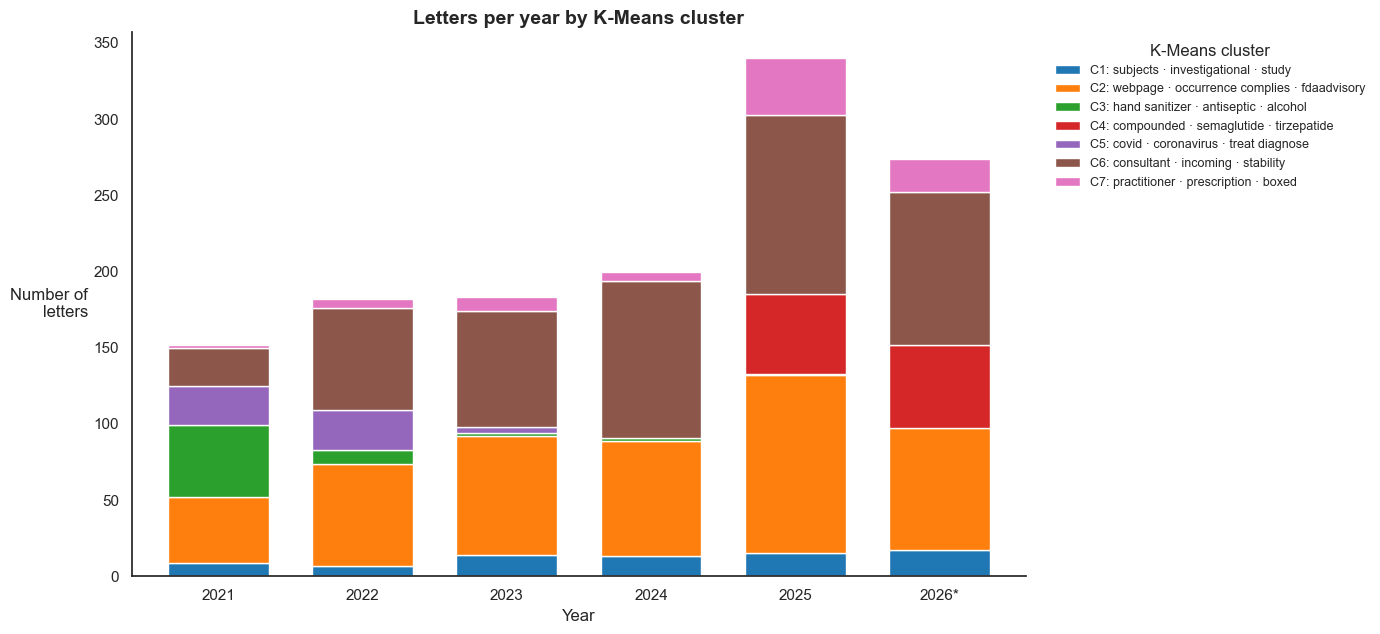

What drove the 2024 → 2025 jump?

By DeBERTa category:
final_topic
Unapproved Drugs & Misbranding    113
cGMP & Manufacturing Quality       14
Drug Compounding                   10
Clinical & Research Violations      2
Unclassified                        1

By K-Means cluster:
kmeans_cluster
C4: compounded · semaglutide · tirzepatide         52
C2: webpage · occurrence complies · fdaadvisory    41
C7: practitioner · prescription · boxed            31
C6: consultant · incoming · stability              15
C1: subjects · investigational · study              2
C5: covid · coronavirus · treat diagnose            0
C3: hand sanitizer · antiseptic · alcohol          -1


In [38]:
year_cluster = (pd.crosstab(letters["year"], letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1]))
                .reindex(years, fill_value=0))
display(year_cluster)

ax = year_cluster.plot(kind="bar", stacked=True, figsize=(14, 6.5), width=0.7,
                       color=km_colors[:year_cluster.shape[1]], edgecolor="white", linewidth=1)
ax.set_xticklabels(xt, rotation=0)
ax.set_title("Letters per year by K-Means cluster", fontsize=14, fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
ax.legend(title="K-Means cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=9)
sns.despine(); plt.tight_layout()
plt.savefig(DATA_DIR / "fda_year_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

print("What drove the 2024 → 2025 jump?")
print("\nBy DeBERTa category:")
print((yearly_counts.loc[2025] - yearly_counts.loc[2024]).rename(DISPLAY).sort_values(ascending=False).to_string())
print("\nBy K-Means cluster:")
print((year_cluster.loc[2025] - year_cluster.loc[2024]).sort_values(ascending=False).to_string())

### 8.6 קטגוריות DeBERTa מול הקבוצות הסמנטיות
בגרסה הקודמת הגרף טען שהקטגוריות של DeBERTa הן "Cluster 1/2/3" בלי שום בדיקה. כאן בודקים את זה באמת.

In [39]:
display(pd.crosstab(letters["semantic_cluster"].map(lambda c: sem_names[c - 1]),
                    letters["final_topic"].map(DISPLAY),
                    rownames=["Semantic cluster"], colnames=["DeBERTa"]))

DeBERTa,Clinical & Research Violations,Drug Compounding,Unapproved Drugs & Misbranding,Unclassified,cGMP & Manufacturing Quality
Semantic cluster,,,,,
C1: semaglutide · claims · advise,0,50,449,0,3
C2: consultant · guidance · contamination,76,37,140,3,573


## 9. שמירת התוצאות והורדה למחשב
שומר טבלה אחת עם כל התוצאות לכל מכתב, ובמחשב של Colab גם מוריד אותה אוטומטית למחשב שלך. אם `SAVE_TO_DRIVE = True`, כל הקבצים כבר נמצאים ב-Google Drive בתיקייה `FDA_project`.

In [40]:
cols = ["url", "company", "date", "year", "office", "subject",
        "kmeans_cluster", "semantic_cluster", "final_topic", "reference_topic"]
results = letters[cols].copy()
results["kmeans_name"]   = results["kmeans_cluster"].map(lambda c: kmeans_names[c - 1])
results["semantic_name"] = results["semantic_cluster"].map(lambda c: sem_names[c - 1])
results.to_csv(RESULTS_OUT, index=False)
print(f"💾 Saved {len(results)} rows to {RESULTS_OUT}")

try:
    from google.colab import files
    for p in [RESULTS_OUT, OFFICES_OUT, DATA_DIR / "fda_yearly_enforcement_trends.png"]:
        files.download(str(p))
except ImportError:
    pass

💾 Saved 1331 rows to data/fda_letters_results.csv


## 10. מסקנות – למלא אחרי הריצה

המסקנות של הגרסה הקודמת נמחקו, כי הן נכתבו לפני התיקונים וחלקן לא נתמכו בנתונים. אחרי הריצה, עונים על השאלות האלה לפי הפלטים:

1. **כמות:** כמה מכתבים רפואיים היו בכל שנה (סעיף 3)? האם יש עלייה, ומה הקצב בשנה החלקית האחרונה?
2. **נושאים:** אילו קבוצות מצאו K-Means (5.3) ו-Sentence-BERT (7.1)? מה ה-FDA עצמו כתב בשדה הנושא של כל קבוצה? האם שתי השיטות מסכימות (7.3)?
3. **כמה קבוצות:** מה ה-k שנבחר לפי Silhouette, וכמה הציון גבוה? (ציון מתחת ל-0.1 בערך = הקבוצות לא מופרדות היטב, וצריך לכתוב את זה.)
4. **מונחים:** מה עולה ברשימה החופשית (4.4 A) לעומת הרשימה הקלינית (B)? האם semaglutide / tirzepatide בולטים גם בלי סינון?
5. **סיווג:** מה הדיוק של DeBERTa מול נושא ה-FDA (8.4)? באילו קטגוריות הוא טועה?
6. **מגמות:** בגרף האחוזים (8.5) – האם החלק של קטגוריה מסוימת עלה או ירד? (לא בגרף המספרים, שמושפע מכמות המכתבים.)
7. **מגבלות:** ההגדרה של "רפואי" (0.4), שדה הנושא כייחוס משוער, שנה אחרונה חלקית, ומספר קטגוריות קטן מאוד בחלק מהקטגוריות.